# Convexity Defects
## Algoritmo para la detección de la tripita de los ratoncillos
13/07/2026 - variación para la revista ARRAY
- Se quiso disminuir el umbral de 10mm (20px) a 5mm (10px), pero los errores son muy altos...

03/09/2026 - cambio de paradigma
- Se toma la distancia respecto a spine_2 y spine_3 del punto detectado en blobs donde no hay solapamiento
- Se analiza cuánto cambia esta distancia cuando sí hay solapamiento (overlapping), respecto a no-overlapping

16/09/2026 - se añade la detección para el dataset moveAI
- Misma metodología, solo que cambian algunos parámetros
- Se incluye un procesamiento de los blobs un poco más complejo, teniendo en cuenta otros parámetros de áreas... MAX/MIN_ELLIPSE_AREA, etc

28/09/2026 - ampliación del algoritmo de detección
- En ciertos casos en el que el blob es muy grande, cuando se detecta una elipse (ratón), su superficie se sustrae del resto del blob y se vuelve a llamar al algoritmo de detección.
- Rediseñar el algoritmo para que vaya por imágenes (frames) y no tanto por blobs, para tener en cuenta que en cada imágen hay NUM_MICE ratones.


## Indice:
- Programa principal: [main](#main_cell)
- Funciones secundarias: [functions](#function_cell)
- Análisis de resultados: [results](#result_cell)


In [6]:
import os
import pandas as pd
#import plotly.express as px
import cv2 as cv
import argparse
import numpy as np
import time
import statistics
from datetime import datetime
from matplotlib import pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde
from scipy.signal import find_peaks
import sklearn.metrics



In [7]:
# Elegir, según el dataset utilizado.
# TriMouse-161
# img_size: 640 x 480 que se reduce a 320 x 240
#ruta_carpeta = r'C:\Users\inges\OneDrive - UDIT\src\photoneu\dataset\deeplabcut\labeled-data-ordered'
#moveAI
# img_size: 1920 x 1080
ruta_carpeta = r'D:\src\photoneu\dataset\moveAI\moveAI_3_mice'

kernel_3 = cv.getStructuringElement(cv.MORPH_ELLIPSE,(3,3))
kernel_5 = cv.getStructuringElement(cv.MORPH_ELLIPSE,(5,5))
RESIZE_FACTOR = 6.0 #1.0 # 2
MAJOR_DEFECT_THRESHOLD = 12.0 / RESIZE_FACTOR #6.0 5.0 12.0
ELLIPSE_RATIO_THRESHOLD = 3.5 # 2.0
NUM_MICE = 3#4

#N = 161 # number of images
N = 602 # number of images
#N = 242 # frames video_2 video_4
#N = 302 # framse video_3
#N = 1801 # framse video_5
#N = 1801 # framse video_6
# img size original: 640 x 480

SEGMENT_COLORS = [(0,255,0),(0,255,255),(255,255,0),(255,0,255)]


In [8]:
df_tmp = pd.DataFrame()
df_times = pd.DataFrame()
nb = []
nm = []
if_overlaps = []
num_inter_points = []
times = []
coord = [None]*3
mus_x = np.full((3,N), None)
mus_y = np.full((3,N), None)
area = np.full((3,N), None)

cols = ["mus_1_x", "mus_1_y", "mus_1_area", "mus_2_x", "mus_2_y", "mus_2_area", "mus_3_x", "mus_3_y", "mus_3_area"]


Leer imágenes de la carpeta

In [9]:
# Lista para almacenar los nombres de los archivos
nombres_imagenes = []

# Recorrer todos los archivos en la carpeta
for archivo in os.listdir(ruta_carpeta):
    # Comprobar si el archivo es una imagen (puedes agregar más extensiones si es necesario)
    if archivo.endswith(('.png', '.jpg', '.jpeg', '.gif', '.bmp', '.tiff', '.webp')):
        archivo = "/"+archivo
        nombres_imagenes.append(archivo)

# Crear un DataFrame de Pandas con los nombres de las imágenes
df = pd.DataFrame(nombres_imagenes, columns=['img_path'])
img = ruta_carpeta + df['img_path'][2]



## Functions used by main program

Para ir al programa principal pulsar [aquí](#main_cell)

In [10]:
def get_img_size(i, ruta_carpeta, img_name):
    """Get the size of an image."""
    img = cv.imread(ruta_carpeta + img_name)
    return img.shape[0], img.shape[1]  # width, height

In [ ]:
def read_image(i, ruta_carpeta, img_name):  
#    img_base = os.path.basename(img_name)
    img_base = os.path.splitext(img_name)[0]
    img_in = ruta_carpeta + img_name
    e1 = cv.getTickCount()
    frame = cv.imread(img_in)
    h,w,_ = frame.shape
    frame_o = frame[x_crop_min:(h-x_crop_max), y_crop_min:(w-y_crop_max)]
    frame = cv.resize(frame_o, (int(normal_size[1]/RESIZE_FACTOR), int(normal_size[0]/RESIZE_FACTOR))) 
    e2 = cv.getTickCount()
    t_init_resize = (e2 - e1)/cv.getTickFrequency()
    return frame

#f = read_image(0, ruta_carpeta, df['img_path'][2])
#print(f.shape) # 240 x 320


In [12]:
def clean_image(frame, thres):
     frame_gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
     frame_norm = cv.normalize(frame_gray, None, alpha = 0, beta = 255, norm_type=cv.NORM_MINMAX)
     frame_blur = cv.medianBlur(frame_norm, 5)
     frame_blur = cv.equalizeHist(frame_blur)
     ret, frame_threshold = cv.threshold( frame_blur, thres, 255, cv.THRESH_BINARY_INV ) #+ cv.THRESH_OTSU )
#     frame_threshold = cv.adaptiveThreshold(frame_blur, 255, 
#                                               cv.ADAPTIVE_THRESH_GAUSSIAN_C, 
#                                               cv.THRESH_BINARY_INV, 11, 2)
     return frame_threshold     


In [13]:
def erode_image(frame):
     frame_erode = cv.morphologyEx(frame, cv.MORPH_DILATE, kernel_3, iterations = 4)  
     opening = cv.morphologyEx(frame_erode, cv.MORPH_OPEN, kernel_3, iterations = 6)


     return opening    

In [14]:
def iou_contour_ellipse(contour, shape):
    mask_contour = np.zeros(shape, dtype=np.uint8)
    mask_ellipse = np.zeros(shape, dtype=np.uint8)

    cv.drawContours(mask_contour, [contour], -1, 255, -1)

    if len(contour) < 5:
        return 0
    ellipse = cv.fitEllipse(contour)
    cv.ellipse(mask_ellipse, ellipse, 255, -1)

    inter = np.logical_and(mask_contour, mask_ellipse).sum()
    union = np.logical_or(mask_contour, mask_ellipse).sum()
    return inter / union if union > 0 else 0

In [15]:
def radial_similarity(contour):
    if len(contour) < 5:
        return 0.0  # fitEllipse necesita >= 5 puntos
    
    # Ajustar la elipse
    ellipse = cv.fitEllipse(contour)
    center = np.array(ellipse[0])   # (x, y)
    axes = np.array(ellipse[1]) / 2 # (a, b) semiejes
    angle = np.deg2rad(ellipse[2])  # rotación en radianes
    
    # Matriz de rotación
    R = np.array([[np.cos(angle), -np.sin(angle)],
                  [np.sin(angle),  np.cos(angle)]])
    
    dists = []
    for p in contour.reshape(-1,2):
        v = p - center
        v_rot = R.T @ v  # rotamos para alinear con la elipse
        theta = np.arctan2(v_rot[1], v_rot[0])
        
        # Radio esperado en la elipse para el ángulo theta
        r_expected = (axes[0]*axes[1]) / np.sqrt((axes[1]*np.cos(theta))**2 +
                                                 (axes[0]*np.sin(theta))**2)
        r_actual = np.linalg.norm(v_rot)
        dists.append((r_actual - r_expected)**2)
    
    rmse = np.sqrt(np.mean(dists))
    Rmax = max(axes)
    
    # Similitud normalizada
    similarity = max(0, 1 - rmse / Rmax)
    return similarity


In [16]:
def similarity_contour_boundingrect(contour):

    if len(contour) < 3:
        return 0.0

    # Bounding rect
    x, y, w, h = cv.boundingRect(contour)
    rect_center = np.array([x + w/2, y + h/2])
    half_w, half_h = w/2, h/2

    dists = []
    for p in contour.reshape(-1,2):
        v = p - rect_center
        theta = np.arctan2(v[1], v[0])

        # Radio esperado para un rectángulo en esa dirección:
        # rectángulo definido por -half_w <= X <= half_w, -half_h <= Y <= half_h
        cos_t, sin_t = np.cos(theta), np.sin(theta)
        # Evitar divisiones por cero
        t1 = half_w / abs(cos_t) if cos_t != 0 else np.inf
        t2 = half_h / abs(sin_t) if sin_t != 0 else np.inf
        r_expected = min(t1, t2)

        r_actual = np.linalg.norm(v)
        dists.append((r_actual - r_expected)**2)

    rmse = np.sqrt(np.mean(dists))

    # Normalización respecto a la semidiagonal (radio máximo posible en el rectángulo)
    r_max = np.sqrt(half_w**2 + half_h**2)
    similarity = 1 - rmse / r_max
    return max(0, similarity)



In [17]:
def detect_blobs(image, ruta_imagen):
#    contours, _ = cv.findContours(image, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    contours, _ = cv.findContours(image, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)
    blobs = []
    for i, contour in enumerate(contours):
        area = cv.contourArea(contour)
        orig_x, orig_y, width, height = cv.boundingRect(contour)
        roi_image = image[orig_y:orig_y+height,orig_x:orig_x+width]
        iou = iou_contour_ellipse(contour, image.shape)
        rs = radial_similarity(contour)
        scb = similarity_contour_boundingrect(contour)
        perimeter = cv.arcLength(contour, True)
        blobs.append({
            "id" : i
            , "img_path": ruta_imagen
            , "n_blobs_in_image": len(contours)
            ,"n_mice": 0
            , "contour" : contour
            , "origin" : (orig_x, orig_y)
            , "size" : (width, height)
            , "roi_image" : roi_image
            , "area" : area
            , "perimeter" : perimeter
            , "iou" : iou
            , "rs": rs
            , "rect_similarity": scb
            , "type": None
            , "ellipses": []
            ,"ellipse_area": []
            ,"hull": None
            ,"split_contours": []
        })
    return blobs
 

In [18]:
"""
Separación recursiva de blobs de ratones solapados a partir del contorno,
usando defectos de convexidad + el área esperada de un ratón como criterio
de validación de cada corte.

Diferencia clave respecto a la versión anterior:
- Antes: se intentaba ajustar un umbral D global para que el número de
  defectos de convexidad "fuertes" coincidiera con min_n_mice, y luego se
  usaban ramas hardcodeadas (0,1,2,3,4,5... puntos) para trocear el
  contorno. Esto es frágil cuando los ratones están muy juntos, porque los
  defectos son débiles y no hay un único D que sirva para todos los cuellos
  a la vez (además la rama de 5 puntos tenía un bug: reusaba
  intersections[2] dos veces).
- Ahora: en cada llamada recursiva solo se resuelve UNA decisión ("¿cuál es
  el mejor ratón para separar del contorno actual?"). Se prueban todos los
  pares de puntos de defecto como cortes candidatos, se ajusta una elipse a
  cada lóbulo candidato, y se compara su área con el área esperada de un
  ratón (mouse_area). El área actúa de árbitro cuando la geometría del
  defecto es ambigua. Se elige el mejor candidato, se separa ese ratón, y se
  recurre sobre el contorno restante para los ratones que faltan.
- Si en algún punto no aparece ningún candidato razonable (fusión casi
  total, sin concavidades visibles), se cae a un fallback por transformada
  de distancia + watershed sobre una máscara reconstruida del blob.

Requiere: numpy, opencv-python. El fallback por watershed usa además scipy
(scipy.ndimage) para detectar máximos locales; si no está disponible en tu
entorno, sustitúyelo por skimage.feature.peak_local_max o quita ese fallback
y deja solo el reparto por arcos iguales.
"""

import numpy as np
import cv2 as cv


# ---------------------------------------------------------------------------
# Utilidades internas
# ---------------------------------------------------------------------------

def _clean_contour(contour):
    """
    Quita puntos duplicados consecutivos (incluido el punto de cierre
    repetido al final) y castea a int32 contiguo. cv.convexityDefects exige
    que los índices del hull sean estrictamente monótonos, y un contorno con
    duplicados (muy habitual tras vstack/slicing) hace que eso falle con
    'convex hull indices are not monotonous'.
    """
    contour = np.asarray(contour, dtype=np.int32).reshape(-1, 2)
    if len(contour) < 2:
        return contour
    keep = np.ones(len(contour), dtype=bool)
    keep[1:] = np.any(contour[1:] != contour[:-1], axis=1)
    contour = contour[keep]
    if len(contour) > 1 and np.array_equal(contour[0], contour[-1]):
        contour = contour[:-1]
    return np.ascontiguousarray(contour)


def _get_defects(contour):
    """
    Devuelve una lista de (indice_en_contorno, score) para cada defecto de
    convexidad del contorno, donde score = distancia_al_hull * anchura del
    defecto (igual métrica que la versión original). No se filtra por ningún
    umbral D aquí: eso se hace luego con min_defect_score, ya como filtro de
    ruido y no como criterio de "cuántos puntos necesito".

    Nota: los índices devueltos son índices dentro del contorno YA LIMPIADO
    (sin duplicados), no del contorno original. Por eso split_blob_contours
    limpia el contorno antes de operar con él, para que los índices sigan
    siendo válidos al cortar.
    """
    contour = _clean_contour(contour)
    if len(contour) < 5:
        return []

    hull_idx = cv.convexHull(contour, returnPoints=False)
    if hull_idx is None or len(hull_idx) < 3:
        return []

    try:
        defects = cv.convexityDefects(contour, hull_idx)
    except cv.error:
        # Contorno degenerado (autointersecciones, colinealidades, etc.):
        # lo tratamos como si no tuviera defectos utilizables, y que el
        # fallback de watershed se encargue de este caso.
        return []
    if defects is None:
        return []

    out = []
    for s, e, f, dist in defects.reshape(-1, 4):
        start = contour[s].astype(float)
        end = contour[e].astype(float)
        width = np.linalg.norm(start - end)
        score = float(dist) * float(width)
        out.append((int(f), score))
    return out


def _cut_contour(contour, i, j):
    """
    Corta el contorno (array Nx2, ordenado tal como sale de findContours) en
    los índices i y j. Devuelve los dos arcos en los que queda dividido: el
    que va de i a j, y el complementario que da la vuelta de j a i. El orden
    de i,j no importa, se normaliza dentro.
    """
    if i > j:
        i, j = j, i
    arco_1 = contour[i:j + 1]
    arco_2 = np.vstack([contour[j:], contour[:i + 1]])
    return arco_1, arco_2


def _try_fit(points, mouse_area, area_tol):
    """
    Ajusta una elipse a `points` y la acepta solo si su área está dentro de
    `area_tol` (relativo) del área esperada de un ratón. Devuelve
    (ellipse, area, error_relativo) o None si no es válido.
    """
    if points is None or len(points) < 5:
        return None
    try:
        ellipse = cv.fitEllipse(points.astype(np.float32))
    except cv.error:
        return None
    (_, _), (MA, ma), _ = ellipse
    area = np.pi * (MA / 2.0) * (ma / 2.0)
    if area <= 0:
        return None
    error = abs(area - mouse_area) / mouse_area
    if error > area_tol:
        return None
    return ellipse, area, error


def _fallback_watershed_split(blob, contour, n_mice, mouse_area):
    """
    Última opción cuando no se encuentran defectos de convexidad útiles
    (ratones casi totalmente solapados, sin concavidades claras). Reconstruye
    una máscara binaria del blob y usa transformada de distancia + watershed
    para separar n_mice regiones, usando el radio esperado de un ratón
    (a partir de mouse_area) para filtrar picos de la transformada de
    distancia.
    """
    x, y, w, h = cv.boundingRect(contour.astype(np.int32))
    pad = 5
    mask = np.zeros((h + 2 * pad, w + 2 * pad), dtype=np.uint8)
    shifted = (contour - [x - pad, y - pad]).astype(np.int32)
    cv.drawContours(mask, [shifted], -1, 255, thickness=-1)

    dist = cv.distanceTransform(mask, cv.DIST_L2, 5)
    mouse_radius = np.sqrt(mouse_area / np.pi)

    try:
        from scipy.ndimage import maximum_filter, label as ndlabel
    except ImportError:
        maximum_filter = None

    n_found = 0
    if maximum_filter is not None:
        footprint = max(3, int(mouse_radius))
        local_max = (dist == maximum_filter(dist, size=footprint)) & (dist > 0.3 * mouse_radius)
        markers, n_found = ndlabel(local_max)

    if n_found >= 2:
        if n_found > n_mice:
            peak_vals = [dist[markers == k].max() for k in range(1, n_found + 1)]
            keep = np.argsort(peak_vals)[::-1][:n_mice] + 1
            clean = np.zeros_like(markers)
            for new_id, old_id in enumerate(keep, start=1):
                clean[markers == old_id] = new_id
            markers = clean

        markers = markers.astype(np.int32) + 1
        markers[mask == 0] = 0
        mask_bgr = cv.cvtColor(mask, cv.COLOR_GRAY2BGR)
        cv.watershed(mask_bgr, markers)

        for k in range(2, markers.max() + 1):
            region = np.uint8(markers == k) * 255
            cnts, _ = cv.findContours(region, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)
            if not cnts:
                continue
            c = max(cnts, key=cv.contourArea).reshape(-1, 2) + [x - pad, y - pad]
            if len(c) >= 5:
                ellipse = cv.fitEllipse(c.astype(np.float32))
                (_, _), (MA, ma), _ = ellipse
                area = np.pi * (MA / 2.0) * (ma / 2.0)
                blob["ellipses"].append(ellipse)
                blob["ellipse_area"].append(area)
                blob["split_contours"].append(c)
        return blob["ellipses"]

    # Ni siquiera el watershed encuentra separación: reparto por longitud de
    # arco a partes iguales (peor caso, pero mejor que devolver menos
    # ratones de los que se sabe que hay).
    n = len(contour)
    step = max(5, n // n_mice)
    for i in range(0, n, step):
        chunk = contour[i:i + step]
        if len(chunk) >= 5:
            ellipse = cv.fitEllipse(chunk.astype(np.float32))
            (_, _), (MA, ma), _ = ellipse
            area = np.pi * (MA / 2.0) * (ma / 2.0)
            blob["ellipses"].append(ellipse)
            blob["ellipse_area"].append(area)
            blob["split_contours"].append(chunk)
    return blob["ellipses"]


# ---------------------------------------------------------------------------
# Función principal (recursiva)
# ---------------------------------------------------------------------------

def split_blob_contours(blob, n_mice, mouse_area, area_tol=0.35,
                         min_defect_score=1.0, _depth=0):
    """
    Separa el contorno de un blob (posible solapamiento de varios ratones)
    en `n_mice` elipses, una por ratón.

    Parámetros
    ----------
    blob : dict
        Debe contener blob["contour"] (Nx1x2 o Nx2, tal como lo da
        cv.findContours). Se van rellenando blob["ellipses"],
        blob["ellipse_area"] y blob["split_contours"] (listas).
    n_mice : int
        Número de ratones que quedan por encontrar en el contorno actual
        (en la llamada de nivel superior, el total de ratones del blob).
    mouse_area : float
        Área aproximada (en píxeles) de un ratón visto desde arriba.
    area_tol : float
        Tolerancia relativa de área para aceptar un candidato de corte
        (0.35 = ±35%). Súbelo si los ratones cambian mucho de área aparente
        (posturas muy estiradas/encogidas), bájalo si tienes falsos
        positivos aceptando cortes que no son un ratón real.
    min_defect_score : float
        Defectos de convexidad con score (dist*anchura) por debajo de esto
        se descartan como ruido del contorno antes de probarlos como cortes.
        Ya no se usa para fijar "cuántos" defectos hacen falta, solo como
        filtro de ruido, así que puedes ponerlo bajo sin miedo a romper la
        cuenta de ratones.

    Devuelve blob["ellipses"] (también accesible tras la llamada).
    """
    blob.setdefault("ellipses", [])
    blob.setdefault("ellipse_area", [])
    blob.setdefault("split_contours", [])

    contour = _clean_contour(blob["contour"])

    # Caso base: el último ratón es lo que queda del contorno actual.
    if n_mice <= 1 or len(contour) < 5:
        if len(contour) >= 5:
            ellipse = cv.fitEllipse(contour.astype(np.float32))
            (_, _), (MA, ma), _ = ellipse
            area = np.pi * (MA / 2.0) * (ma / 2.0)
            blob["ellipses"].append(ellipse)
            blob["ellipse_area"].append(area)
            blob["split_contours"].append(contour)
        return blob["ellipses"]

    defects = [d for d in _get_defects(contour) if d[1] >= min_defect_score]

    best = None  # (score, lobulo, resto, ellipse, area)
    for a in range(len(defects)):
        for b in range(len(defects)):
            if a == b:
                continue
            i, score_i = defects[a]
            j, score_j = defects[b]
            if i == j:
                continue

            lobulo, resto = _cut_contour(contour, i, j)
            if len(resto) < 5:
                continue

            fit = _try_fit(lobulo, mouse_area, area_tol)
            if fit is None:
                continue
            ellipse, area, area_error = fit

            # combinamos la fuerza de los dos defectos que delimitan el
            # cuello con la calidad del ajuste de área
            defect_strength = min(score_i, score_j)
            score = defect_strength / (1.0 + 5.0 * area_error)

            if best is None or score > best[0]:
                best = (score, lobulo, resto, ellipse, area)

    if best is None:
        # Ningún par de defectos produce un lóbulo del tamaño de un ratón:
        # probablemente están demasiado fusionados para este método.
        return _fallback_watershed_split(blob, contour, n_mice, mouse_area)

    _, lobulo, resto, ellipse, area = best
    blob["ellipses"].append(ellipse)
    blob["ellipse_area"].append(area)
    blob["split_contours"].append(lobulo)

    blob["contour"] = resto
    return split_blob_contours(blob, n_mice - 1, mouse_area, area_tol,
                                min_defect_score, _depth + 1)

In [19]:
# Radial Similarity Score. Cuánto se parece el contorno a una elipse
def gen_rss(type_blob):
    print("Generating RSS for type %d" % type_blob)
    rss = []
    total_blobs_flat = [d for sublist in total_blobs for d in sublist]
    #for blobs in total_blobs:
    blobs_sorted = sorted(total_blobs_flat, key=lambda x: x["area"], reverse=True)
    #    for blob in blobs_sorted:
    for blob in blobs_sorted:
        if blob["type"] == type_blob:
            rss.append(blob["rs"])
    return rss
#rss = []
#labels = ["noise blobs", "single mice", "overlapping mice"]
#for t in [0,1,2]:
#    rss.append(gen_rss(t))
#plt.figure(figsize=(8,4))
#for i, rss in enumerate (rss):
#    plt.plot(range(len(rss)), rss, linestyle="-")
#    plt.text( 2*len(rss)/3, 0.9 - i*0.1, labels[i], fontsize=12, color="black")
##    plt.text(len(rss)-1, rss[-1], f"{rss[-1]:.2f}")
##    plt.text(i * len(rss), rss[-1] - 0.1, f"Type {i}", fontsize=12, color="black")
#plt.xlabel("contoursorted by decreasing area")
#plt.grid(True)
#plt.ylim(0.5,1)
#plt.show()

In [20]:
def fit_ellipse_to_contour(blob):
    """
    Ajusta una elipse a un contorno dado y devuelve la elipse ajustada y su área.
    """
    if len(blob["contour"]) < 5:
        return None, None  # No se puede ajustar una elipse con menos de 5 puntos
    ellipse = cv.fitEllipse(blob["contour"].astype(np.float32))
    (_, _), (MA, ma), _ = ellipse
    area = np.pi * (MA / 2.0) * (ma / 2.0)
    blob["ellipse_area"].append(area)
    blob["ellipses"].append(ellipse) 

    return ellipse, area

In [21]:
# split contour using convexity defects and number of mice to detect
def split_blob_contours_v1(blob, min_n_mice):
    print("Splitting blob contours for min_n_mice:", min_n_mice)
    D = 20000
    num_ellipses = 0
    D_min = 10
    D_max = 10e6
    D_change_factor = 0.1
    min_n_points = min_n_mice 
#    max_n_points = (min_n_mice - 1) * 2 + 1 
    if min_n_mice == 1:
        print("Single mouse detected, fitting ellipse directly.")
        c = blob["contour"]
        if len(c) >= 5:
             e = cv.fitEllipse(c)
             ea = (np.pi * (e[1][0]/2) * (e[1][1]/2  ))
             if areas["min_ellipse_area"] < ea < areas["max_ellipse_area"]: #and max(e[1][0], e[1][1]) / min(e[1][0],e[1][1]) < ELLIPSE_RATIO_THRESHOLD:
                blob["ellipse_area"].append(ea)
                blob["ellipses"].append(e) 
                return blob["ellipses"]
             else:
                 print("Ellipse area out of range for single mouse:", ea)
                 return None
        else:
            print("Contour too small for single mouse:", len(blob["contour"]))
            return None
#    else:    
    max_n_points = min_n_mice
    contour = blob["contour"]
    contour = contour.squeeze()  # Elimina dimensiones extra si es necesario
    contour.tolist()
    contour = _clean_contour(contour) # Elimina puntos duplicados
    blob["hull"] = cv.convexHull(contour)

    hull_idx = cv.convexHull(contour, returnPoints=False)
    try:
        defects = cv.convexityDefects(contour, hull_idx) 
    except cv.error as e:
        print("Error computing convexity defects:", e)
        defects = None
        return None

    #defects are: [start_point, end_point, far_index, distance]
    # - start_point / end_point: closest points where convexHull and countour match
    # - far_index: index to the point of the contour with maximum distance to convexHull (between start and end)
    # - distance: between convexHull and contour point far_index.

    scores = np.zeros(len(blob["contour"]))

    intersections = []
    inter_points = []
    split_contours = []
    widths = []
    distances = []
    D_final = []
    n_points = 0
    if defects is not None :
#        print("defects:", defects)
        for i, defect in enumerate(np.squeeze(defects, 1)):#defects.shape[0]):
          s,e,f,dist= defect
          start = tuple(contour[s])
          end = tuple(contour[e])
          far = tuple(contour[f])
          width = np.linalg.norm(np.array(start) - np.array(end))
          scores[f] = dist*width
        n_points_old = 0
        n_iterations = 0
        while True:
            n_points = np.sum(scores >= D)
            print("n_points:", n_points)    
            if D < D_min or D > D_max: # por si acaso
              print("D out of range, stopping")
              break 
            # vamos incrementadon o o decrementando D hasta tener el numero de puntos deseado
            # para evitar bucles infinitos, vamos modificando el factor de cambio                
            else:
                if n_points > max_n_points: # too many points
                  D = D * (1 + D_change_factor)
                  print("Increasing D to:", D)
                elif n_points < min_n_points: # too few points
                  D = D * (1- D_change_factor)
                  print("Decreasing D to:", D)
                else:   # just right    
                    break
                if n_points == n_points_old:
                    D_change_factor *= 1.1 # increase change factor to escape oscillations
                elif n_points != n_points_old:
                    D_change_factor /= 1.1 # reduce change factor to avoid oscillations
            n_points_old = n_points
            n_iterations += 1
            if n_iterations > 100:
                print("Too many iterations, stopping")
                break
        print("Final D:", D)
        D_final.append(D)
        widths.append(width)
        distances.append(dist)
        D_change_factor = 0.1

        for i, defect in enumerate(np.squeeze(defects, 1)):#defects.shape[0]):
            s,e,f,dist= defect
            far = tuple(contour[f])
            if (scores[f] ) >= D: #MAJOR_DEFECT_THRESHOLD
               intersections.append(f)
               inter_points.append(far)
    intersections.sort()
    if n_points != len(intersections):
        print("Warning: n_points != len(intersections)")
        n_points = len(intersections)
        
    if (n_points == 0): # No se detectan defectos de convexidad
        print("No convexity defects detected.")
        split_contours = [contour]
    elif n_points == 1:
        index_plus = intersections[0] + len(contour)//2
        index_less = intersections[0] - len(contour)//2
        if intersections[0] < len(contour)//2:
            blob["segments"] = [
                contour[intersections[0]:index_plus]
                , np.vstack([contour[index_plus:],contour[:intersections[0]+1]])
    #            ,contour[midle_index:] + contour[:intersections[0]]
            ]
        else:
            blob["segments"] = [
                np.vstack([contour[intersections[0]:],contour[:index_less]])
                ,contour[index_less:intersections[0]+1]
                ]
        split_contours = [
            blob["segments"][0], blob["segments"][1]
        ]
    elif n_points == 2:
        if intersections[0] > intersections[1]:
            intersections[0], intersections[1] = intersections[1], intersections[0]
        blob["segments"] = [
                contour[intersections[0]:intersections[1]+1]
                , np.vstack([contour[intersections[1]:],contour[:intersections[0]+1]])
            ]
        blob["segments"] = [
            contour[intersections[0]:intersections[1]+1]
            , np.vstack([contour[intersections[1]:],contour[:intersections[0]+1]])
        ]
        split_contours = [
            blob["segments"][0], blob["segments"][1]
        ]
    elif n_points == 3:
        blob["segments"] = [
            contour[intersections[0]:intersections[1]+1]
            , contour[intersections[1]:intersections[2]+1]
            , np.vstack([contour[intersections[2]:],contour[:intersections[0]+1]])
        ]
        split_contours = [
            blob["segments"][0], blob["segments"][1], blob["segments"][2]
        ]
    elif n_points == 4:
        blob["segments"] = [
            contour[intersections[0]:intersections[1]+1]
            , contour[intersections[1]:intersections[2]+1]
            , contour[intersections[2]:intersections[3]+1]
            , np.vstack([contour[intersections[3]:],contour[:intersections[0]+1]])
        ]
        split_contours = [
            blob["segments"][0], blob["segments"][1],blob["segments"][2], blob["segments"][3]
        ]
    elif n_points == 5:
        blob["segments"] = [
            contour[intersections[0]:intersections[1]+1]
            , contour[intersections[1]:intersections[2]+1]
            , contour[intersections[2]:intersections[3]+1]
            , contour[intersections[3]:intersections[4]+1]
            , np.vstack([contour[intersections[4]:],contour[:intersections[0]+1]])
        ]
        split_contours = [
            blob["segments"][0], blob["segments"][1],blob["segments"][2], blob["segments"][3], blob["segments"][4]
        ]
    else :
       for i in range(0,len(contour),n_points):
          split_contour = contour[i:i + n_points]
          if len(split_contour) > 5:
             split_contours.append(split_contour)
    blob["split_contours"] = split_contours
    for c in split_contours:
        if len(c) >= 5:
            e = cv.fitEllipse(c)
            ea = (np.pi * (e[1][0]/2) * (e[1][1]/2  ))
            if areas["min_ellipse_area"] < ea < areas["max_ellipse_area"]: #and max(e[1][0], e[1][1]) / min(e[1][0],e[1][1]) < ELLIPSE_RATIO_THRESHOLD:
                blob["ellipse_area"].append(ea)
                blob["ellipses"].append(e) 
                num_ellipses += 1
    # Si el número de elipses detectadas es menor que el número mínimo de ratones esperado, se imprime un mensaje de advertencia.   
    # se eliminan en el blob los píxeles de las elipses detectadas y se vuelve a llamar a la función
    # con el contorno restante para intentar detectar más elipses hasta alcanzar el número mínimo de ratones esperado.
    if 0 < num_ellipses < min_n_mice:
        print("Not enough ellipses detected for blob in file:", blob["img_path"])
        print("Detected ellipses:", num_ellipses, "Expected:", min_n_mice)
        blob["n_mice"] = blob["n_mice"] - num_ellipses 
        
        # borramos los píxeles de las elipses detectadas del contorno original
        new_roi = blob["roi_image"].copy()
        mask = np.zeros_like(new_roi, dtype=np.uint8)
        factor = 1.1 
        for e in blob["ellipses"]:
            #trasladamos la elipse segun las coordenadas del blob:
            c, s, a = e
            c = (e[0][0] - blob["origin"][0], e[0][1] - blob["origin"][1])
            s = (s[0]*factor, s[1]*factor)  
            new_e = (c, s, a)
            cv.ellipse(mask, new_e, 255, -1)
        # obtenemos el contorno restante
        new_roi[mask == 255] = 0
        blob["roi_image"] = new_roi.copy()

        remaining_contour, _ = cv.findContours(new_roi, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)
        if remaining_contour:
            blob["contour"] = max(remaining_contour, key=cv.contourArea)
            # trasladamos el origen de blob["contour"] a las coordenadas originales del blob
            blob["contour"] += np.array(blob["origin"])
            # volvemos a llamar a la función con el contorno restante
            split_blob_contours_v1(blob, min_n_mice - num_ellipses) 
        else:
            print("No remaining contour found after removing detected ellipses.")
    blob["intersections"] = intersections    
    blob["inter_points"] = inter_points   
    blob["widths"] = widths
    blob["distances"] = distances
    blob["D_final"] = D_final
    
    return blob["ellipses"]

In [22]:
# split contour v0 using convexity defects and a minimum of mice to detect
def split_blob_contours_v0(blob, D, min_n_mice):
    min_n_points = (min_n_mice - 1) * 2 
    contour = blob["contour"]
    contour = contour.squeeze()  # Elimina dimensiones extra si es necesario
    contour.tolist()
    blob["hull"] = cv.convexHull(contour)

    hull_idx = cv.convexHull(contour, returnPoints=False)
    defects = cv.convexityDefects(contour, hull_idx) 
    #defects are: [start_point, end_point, far_index, distance]
    # - start_point / end_point: closest points where convexHull and countour match
    # - far_index: index to the point of the contour with maximum distance to convexHull (between start and end)
    # - distance: between convexHull and contour point far_index.

    distancias = np.zeros(len(blob["contour"]))
    widths = np.zeros(len(blob["contour"]))
    scores = np.zeros(len(blob["contour"]))

    intersections = []
    inter_points = []
    split_contours = []
    if defects is not None :
#        print("defects:", defects)
        for i, defect in enumerate(np.squeeze(defects, 1)):#defects.shape[0]):
          s,e,f,dist= defect
          start = tuple(contour[s])
          end = tuple(contour[e])
          far = tuple(contour[f])
          distancias[f] = dist
          width = np.linalg.norm(np.array(start) - np.array(end))
          widths[f] = width
          scores[f] = dist*width
        while True:
            n_points = np.sum(scores >= D)
            print("n_points:", n_points)    
            if n_points > min_n_points: # too many points
              D = D * 1.1
              print("Increasing D to:", D)
            elif n_points < min_n_points: # too few points
              D = D * 0.9
              print("Decreasing D to:", D)
            else:   # just right    
                break
        print("Final D:", D)
        for i, defect in enumerate(np.squeeze(defects, 1)):#defects.shape[0]):
            s,e,f,dist= defect
            far = tuple(contour[f])
            if (scores[f] ) >= D: #MAJOR_DEFECT_THRESHOLD
               intersections.append(f)
               inter_points.append(far)
    intersections.sort()
    print("n_inflection_points:", len(intersections))
    print("len(contour):", len(contour))
    if n_points != len(intersections):
        print("Warning: n_points != len(intersections)")
        n_points = len(intersections)

    if (n_points == 0): # No se detectan defectos de convexidad
        print("No convexity defects detected.")
        split_contours = [contour]
    elif n_points == 1:
        print("intersections[0]:", intersections[0])
        print("len(contour):", len(contour))
        print("len(contour)//2:", len(contour)//2)
        index_plus = intersections[0] + len(contour)//2
        index_less = intersections[0] - len(contour)//2
        if intersections[0] < len(contour)//2:
            blob["segments"] = [
                contour[intersections[0]:index_plus]
                , np.vstack([contour[index_plus:],contour[:intersections[0]+1]])
    #            ,contour[midle_index:] + contour[:intersections[0]]
            ]
        else:
            blob["segments"] = [
                np.vstack([contour[intersections[0]:],contour[:index_less]])
                ,contour[index_less:intersections[0]+1]
                ]
        split_contours = [
            blob["segments"][0], blob["segments"][1]
        ]
    elif n_points == 2:
        print("intersections[0]:", intersections[0])
        print("intersections[1]:", intersections[1])
        if intersections[0] > intersections[1]:
            intersections[0], intersections[1] = intersections[1], intersections[0]
        blob["segments"] = [
                contour[intersections[0]:intersections[1]+1]
                , np.vstack([contour[intersections[1]:],contour[:intersections[0]+1]])
            ]
        blob["segments"] = [
            contour[intersections[0]:intersections[1]+1]
            , np.vstack([contour[intersections[1]:],contour[:intersections[0]+1]])
        ]
        split_contours = [
            blob["segments"][0], blob["segments"][1]
        ]
    elif n_points == 3:
        print("intersections[0]:", intersections[0])
        print("intersections[1]:", intersections[1])
        print("intersections[2]:", intersections[2])

        blob["segments"] = [
            contour[intersections[0]:intersections[1]+1]
            , contour[intersections[1]:intersections[2]+1]
            , np.vstack([contour[intersections[2]:],contour[:intersections[0]+1]])
        ]
        split_contours = [
            blob["segments"][0], blob["segments"][1], blob["segments"][2]
        ]
    elif n_points == 4:
        print("intersections[0]:", intersections[0])
        print("intersections[1]:", intersections[1])
        print("intersections[2]:", intersections[2])
        print("intersections[3]:", intersections[3])
        blob["segments"] = [
            contour[intersections[0]:intersections[1]+1]
            , contour[intersections[1]:intersections[2]+1]
            , contour[intersections[2]:intersections[3]+1]
            , np.vstack([contour[intersections[3]:],contour[:intersections[0]+1]])
        ]
        split_contours = [
            blob["segments"][0], blob["segments"][1],blob["segments"][2], blob["segments"][3]
        ]
    elif n_points == 5:
        blob["segments"] = [
            contour[intersections[0]:intersections[1]+1]
            , contour[intersections[1]:intersections[2]+1]
            , contour[intersections[2]:intersections[3]+1]
            , contour[intersections[3]:intersections[4]+1]
            , np.vstack([contour[intersections[4]:],contour[:intersections[0]+1]])
        ]
        split_contours = [
            blob["segments"][0], blob["segments"][1],blob["segments"][2], blob["segments"][3], blob["segments"][4]
        ]
    else :
       for i in range(0,len(contour),n_points):
          split_contour = contour[i:i + n_points]
          if len(split_contour)> 5:
             split_contours.append(split_contour)
    blob["split_contours"] = split_contours
    for c in split_contours:
        print("split_contour_len:", len(c))
        if len(c) >= 5:
            e = cv.fitEllipse(c)
            blob["ellipses"].append(e) 
            blob["ellipse_area"].append((np.pi * (e[1][0]/2) * (e[1][1]/2  )))
    blob["intersections"] = intersections    
    blob["inter_points"] = inter_points    
    
    return blob["ellipses"]

In [23]:
# analizamos los blobs en función del área y en función de si hay otros blobs en la imagen que tengan un área similar. Esto nos permite clasificar los blobs en 4 tipos:

def process_blob(blob):
    if blob["area"] < areas["min_mice_area"]:
        blob["type"] = 0 # small blob. Probably noise. No mice
    else:
        blob["type"] = b["n_mice"]  # just one mice
        if blob["type"] == 1:
            fit_ellipse_to_contour(blob)
        if blob["type"] > 1: # probably more tan 1 mice
            split_blob_contours_v1(blob,blob["n_mice"])


In [24]:
def display_results(image, blobs, thres, write_image_flag=False):
    SEGMENT_COLORS = [(0,255,0),(0,255,255),(255,255,0),(255,0,255)]
    output = image.copy()
    for blob in blobs:
        color = (0, 255, 0) if blob["type"] == 0 else (0, 255, 255) if blob["type"] == 1 else (255, 0, 0) if blob["type"] == 2 else (0, 0, 255)  
#        cv.drawContours(output, [blob["contour"]], -1, color, 2)
        x, y = blob["origin"]
        w, h = blob["size"]
        cv.rectangle(output, (x, y), (x + w, y + h), color, 1)
        cv.putText(output, f'{int(blob["area"])}', (x, y - 5), cv.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)
#        cv.putText(output, f'ID:{blob["id"]} A:{int(blob["area"])}', (x, y - 10), cv.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
        
        if blob["hull"] is not None:
            cv.drawContours(output, [blob["hull"]], -1, (255, 0, 255), 1)
        
        for ellipse in blob["ellipses"]:
            if ellipse is not None:
                #ellipse_area = (np.pi * (blob["ellipses"][-1][1][0]/2) * (blob["ellipses"][-1][1][1]/2))
                ellipse_area = (np.pi * (ellipse[1][0]/2) * (ellipse[1][1]/2))
                iou = blob.get("iou", 0.0)
                if ellipse_area > areas["min_ellipse_area"]:
                    cv.ellipse(output, ellipse, (255,30,25), 1)
                    cv.circle(output,(int(ellipse[0][0]),int(ellipse[0][1])), 3, (255,255,25))
                    cv.putText(output,str(int(ellipse_area)),(int(ellipse[0][0]+10),int(ellipse[0][1]-5)), cv.FONT_HERSHEY_SIMPLEX, 0.6,(100,255,20),1)# Add character description
#                    cv.putText(output,f"{iou:.2f}",(int(ellipse[0][0]),int(ellipse[0][1]+20)), cv.FONT_HERSHEY_SIMPLEX, 0.6,(100,255,20),1)# Add character description
#                    cv.putText(output,str(int(ellipse[0][0]))+","+str(int(ellipse[0][1])),(int(ellipse[0][0]-40),int(ellipse[0][1]+20)), cv.FONT_HERSHEY_SIMPLEX, 0.6,(100,255,20),1)# Add character description
#                cv.putText(output,str(int(blob["area"])),(int(ellipse[0][0]+10),int(ellipse[0][1]-5)), cv.FONT_HERSHEY_SIMPLEX, 0.6,(100,255,20),1)# Add character description

        
        if blob["split_contours"]:
            for n, split_contour in enumerate(blob["split_contours"]):
                cv.polylines(output, [split_contour], False, SEGMENT_COLORS[n%4], 2)   

        if "inter_points" in blob:
            for point in blob["inter_points"]:
                cv.circle(output, point, 3, (0, 0, 255))

    if write_image_flag:
        img_out = ruta_carpeta + "/img_results/"+ str(thres) +"/"
        try:
            os.mkdir(img_out)
        except Exception as e:
            print(f"{e}")
        img_out += blob["img_path"].replace("/","")  
        print(img_out)
        cv.imwrite(img_out,output)

    plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB))
    plt.tight_layout()
    plt.show()


<a id='main_cell'></a>

## MAIN program

Execute above cells

In [33]:
# test 1 frame
# TriMouse
#ruta_imagen = r'/img0734.png'
#ruta_imagen = r'/img1246b.png'
#ruta_imagen = r'/img0705.png'
# 3 mice
#ruta_imagen = r'/240712_3w_148b_151b_154b_m_rec_1000model_mp4-0217_jpg.rf.42e6e12fa3b10f4d122bf6d31281f10d.jpg'
# 4 mice
#ruta_imagen = r'/240712_3w_148b_151b_154b_m_rec_1000model_mp4-0030_jpg.rf.8ec984dcc3b67079c5e899d6030cc230.jpg'
#ruta_imagen = r'/240712_3w_148b_151b_154b_m_rec_1000model_mp4-0069_jpg.rf.049675682e7a7284cae5c173ac06e680.jpg'
#ruta_imagen = r'/240712_3w_148b_151b_154b_m_rec_1000model_mp4-0024_jpg.rf.908e67870465c5fd6299944b0edc902c.jpg'
#ruta_imagen = r'/240712_3w_148b_151b_154b_m_rec_1000model_mp4-0178_jpg.rf.e60d251fabcec44d094f8289abfb9153.jpg'
ruta_imagen = r'/240712_3w_148b_151b_154b_m_rec_1000model_mp4-0084_jpg.rf.5deb388331fbcb09e124631359d4e7af.jpg'
normal_size = get_img_size(0, ruta_carpeta, ruta_imagen)
print("normal_size:", normal_size)
#normal_size = (480, 640)


normal_size: (1080, 1920)


Found  1 blob(s).
blob area = 5002
iou = 0.70
rs = 0.83
rect_similarity = 0.71
Splitting blob contours for min_n_mice: 3
n_points: 4
Increasing D to: 22000.0
n_points: 4
Increasing D to: 24000.0
n_points: 4
Increasing D to: 26400.000000000004
n_points: 4
Increasing D to: 29304.000000000007
n_points: 4
Increasing D to: 32849.78400000001
n_points: 4
Increasing D to: 37222.090250400004
n_points: 4
Increasing D to: 42671.77648396107
n_points: 4
Increasing D to: 49544.10875847949
n_points: 4
Increasing D to: 58321.14984410756
n_points: 4
Increasing D to: 69686.29204339503
n_points: 4
Increasing D to: 84624.1676268564
n_points: 3
Final D: 84624.1676268564
Not enough ellipses detected for blob in file: /240712_3w_148b_151b_154b_m_rec_1000model_mp4-0084_jpg.rf.5deb388331fbcb09e124631359d4e7af.jpg
Detected ellipses: 2 Expected: 3
Splitting blob contours for min_n_mice: 1
Single mouse detected, fitting ellipse directly.


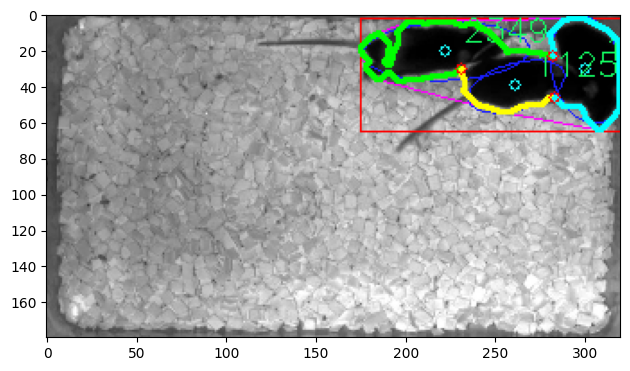

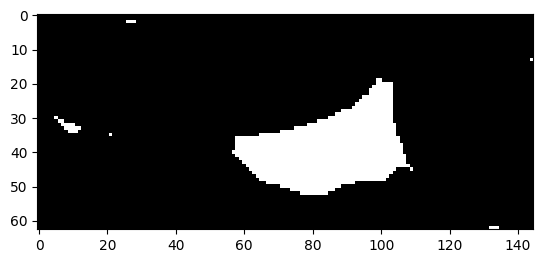

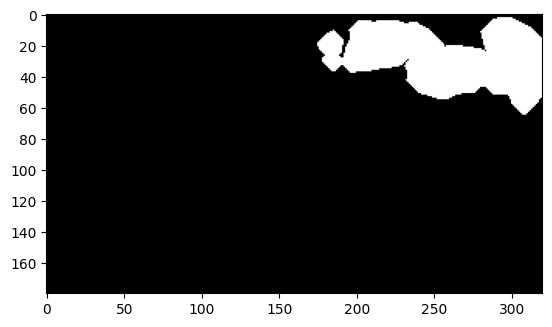

In [ ]:

# TriMouse
#x_crop_min = int(normal_size[1]/19) #50
#x_crop_max = int(normal_size[1]/25) # 30
#y_crop_min = int(normal_size[0]/20) # 30
#y_crop_max = int(normal_size[0]/20) # 16 -- 40

# moveAI dataset
x_crop_min = int(normal_size[1]/12)#int(normal_size[1]/10) #50
x_crop_max = int(normal_size[1]/14)#int(normal_size[1]/20) # 30
y_crop_min = int(normal_size[0]/6)#int(normal_size[0]/16) # 30
y_crop_max = int(normal_size[0]/4) #int(normal_size[0]/20) # 16 -- 40

#TriMouose
#BW_THRES = 10 # min B/W value for threshold. Hay que calibrarlo
# moveAI dataset
#BW_THRES = 8 # Cuanto más grande más pixeles entran como blancos
BW_THRES = 12 # min B/W value for threshold. Hay que calibrarlo

thres = BW_THRES

frame = read_image(0, ruta_carpeta, img_name = ruta_imagen)
clean_frame = clean_image(frame, thres)
clean_frame = erode_image(clean_frame)

blobs = detect_blobs(clean_frame, ruta_imagen)
print("Found %2d blob(s)." % len(blobs))
for b in blobs:
    print("blob area = %2d" % b["area"])
    print("iou = %.2f" % b["iou"])
    print("rs = %.2f" % b["rs"])
    print("rect_similarity = %.2f" % b["rect_similarity"])
#    plt.imshow(cv.cvtColor(b["roi_image"], cv.COLOR_BGR2RGB))
#    plt.show()

hist = cv.calcHist([clean_frame], [0], None, [256], [0,256])

# test get ellipse from convexity defects, then extract ellipse from ROI blob and display new ROI
areas = {'min_mice_area': 463.0951617607253, 'max_mice_area': 1994.3319762430358, 'mean_mice_area': 1228.7135690018806, 'min_ellipse_area': 231.54758088036266, 'max_ellipse_area': 2520.69463122133, 'mean_ellipse_area': 0, 'area_peaks': [463.0951617607253, 1994.3319762430358, 3047.0572861996243, 3940.2787613143055]}
split_blob_contours_v1(blobs[0], 3)
display_results(frame, blobs, thres, False)

plt.imshow(cv.cvtColor(blobs[0]["roi_image"], cv.COLOR_BGR2RGB))
plt.show()

plt.imshow(cv.cvtColor(clean_frame, cv.COLOR_BGR2RGB))
plt.show()



In [36]:
frame.shape

(180, 320, 3)

In [28]:
# Compute all frames
# Detect blobs and their areas
thres = BW_THRES
total_areas = []
total_blobs = []
for i, img in enumerate(df['img_path']):
    frame = read_image(i, ruta_carpeta, img)
    clean_frame = clean_image(frame, thres)
    clean_frame = erode_image(clean_frame)
    blobs = detect_blobs(clean_frame, img)
    # show number of blobs and image name
#    print("Image:", img, " - Found %2d blob(s)." % len(blobs))
    total_blobs.append(blobs)
    for b in blobs:
#        print("blob area = %2d" % b["area"])
#        if b["area"] < 3000:
        total_areas.append(int(b["area"]))
#        process_blob(b)
#    display_results(frame, blobs, thres, write_image_flag=True)

{'min_mice_area': 396.20085606139264, 'max_mice_area': 1924.2955118019418, 'mean_mice_area': 1160.2481839316672, 'min_ellipse_area': 198.10042803069632, 'max_ellipse_area': 2367.4429619667008, 'mean_ellipse_area': 0, 'area_peaks': [396.20085606139264, 1924.2955118019418, 2810.59041213146, 3758.0090986906007]}


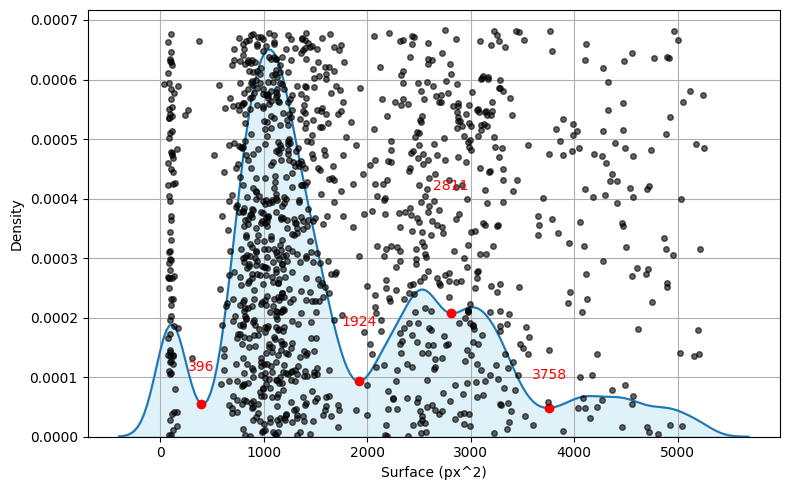

In [29]:
from scipy.signal import find_peaks
areas = {
    "min_mice_area":0,
    "max_mice_area":0,
    "mean_mice_area":0,
    "min_ellipse_area":0,
    "max_ellipse_area":0,
    "mean_ellipse_area":0,
    "area_peaks":[]
    }

fig, ax = plt.subplots( figsize=(8,5) )

#x = np.linspace(min(total_areas)-1, max(total_areas)+1, 10)

sns.kdeplot(total_areas, fill=True, bw_adjust=0.5, color="skyblue")
kde = sns.kdeplot(total_areas, bw_adjust=0.5).get_lines()[0].get_data()
#plt.cla()  # limpiar para graficar de nuevo sin duplicados

xk, yk = kde
peaks, _ = find_peaks(1-yk)

# Calcular frecuencia real de cada valor
valores_unicos, frecuencias = np.unique(total_areas, return_counts=True)

# Dibujar los máximos locales con anotaciones
for p in peaks:
    xpeak, ypeak = xk[p], yk[p]
    areas["area_peaks"].append(xpeak)
    # Buscar el entero más cercano en tus datos
    idx = (np.abs(valores_unicos - xpeak)).argmin()
    freq = frecuencias[idx]
    plt.plot(xpeak, ypeak, "ro")
    plt.text(xpeak * (1), ypeak* (2 ), f"{xpeak:.0f}", ha="center", color="red")

areas["min_mice_area"] = xk[peaks][0] #1973 #545 #702
areas["max_mice_area"] = xk[peaks][1] 
areas["mean_mice_area"] = (xk[peaks][0] + xk[peaks][1]) / 2
areas["min_ellipse_area"] = xk[peaks][0] / 2
areas["max_ellipse_area"]  = (xk[peaks][1] + xk[peaks][2]) / 2 #7683# 2214 #2462
print(areas)

#print(f"MIN_AREA: {areas["min_mice_area"]}")
#print(f"MAX_AREA: {areas["max_mice_area"]}")
#print(f"MIN_ELLIPSE_AREA: {areas["min_ellipse_area"]}")
#print(f"MAX_ELLIPSE_AREA: {areas["max_ellipse_area"]}")
#print(f"area_peaks: {areas["area_peaks"]}")
y_max = ax.get_ylim()[1]
jitter_height = y_max * 1  # 5% de la altura del gráfico
y_jitter = np.random.uniform(0, jitter_height, size=len(total_areas))

#x_min, x_max = min(total_areas)-1, MAX_AREA+1
#ax.set_xlim(x_min, x_max)

ax.plot(total_areas, y_jitter, "o", alpha=0.6, color="black", markersize=4)
ax.set_xlabel("Surface (px^2)")
ax.grid(True)

plt.tight_layout()
#plt.title("Distribución de valores (Boxplot)")
plt.show()


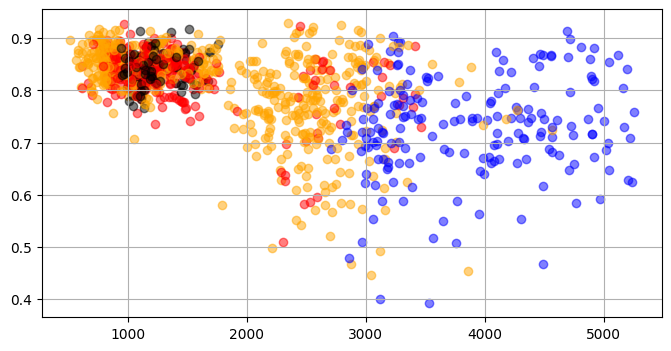

In [30]:
# Representación gráfica ´que relaciona el iou de cada blob con su área. Se puede usar para determinar un umbral de área
fig, ax = plt.subplots(figsize=(8, 4))
for blobs in total_blobs:
    # definimos color segun el numero de blobs en la misma imagen que tengan un area mayor a min_mice_area. Si hay un solo blob, es azul, si hay dos, naranja, si hay tres, rojo y si hay más de tres, negro.
    color = 'blue' if len(blobs) == 1 else 'orange' if len(blobs) == 2 else 'red' if len(blobs) == 3 else 'black'
    for blob in blobs:
        if blob["area"] > areas["min_mice_area"]:
#            ax.scatter(blob["perimeter"], blob["iou"], color='green', alpha=0.5)  
            ax.scatter(blob["area"], blob["iou"], color=color, alpha=0.5)  
ax.grid(True)

In [31]:
areas

{'min_mice_area': 396.20085606139264,
 'max_mice_area': 1924.2955118019418,
 'mean_mice_area': 1160.2481839316672,
 'min_ellipse_area': 198.10042803069632,
 'max_ellipse_area': 2367.4429619667008,
 'mean_ellipse_area': 0,
 'area_peaks': [396.20085606139264,
  1924.2955118019418,
  2810.59041213146,
  3758.0090986906007]}

In [32]:
# Analizamos cada blob en por imágenes según haya 1, 2, o 3 blobs grandes en cada imagen.
# Si hay 1 solo blob grande en la imagen, entonces el número de ratones es NUM_MICE
# Si hay 2 blobs grandes en la imagen, en el blob pequeño habrá 1 ratón y NUM_MICE - 1 en el blob grande
# Si hay 3 blobs grandes en la imagen, en cada blob habrá 1 único ratón.
n_mice = NUM_MICE
for blobs in total_blobs: # recorre imagenes
    # especificamos el número de ratones en cada blob repartiendo NUM_MICE 
    # según el número de blobs grandes en la imagen y su tamaño relativo.
    num_large_blobs = sum(1 for b in blobs if b["area"] > areas["min_mice_area"])
    if num_large_blobs == 1:
        for b in blobs:
            if b["area"] > areas["min_mice_area"]:      
                b["n_mice"] = 3
    elif num_large_blobs == 2:
        #tenemos dos blobs grandes, el de mayor área tendra 2 mice el otro 1:
        blobs_sorted = sorted(blobs, key=lambda x: x["area"], reverse=True)
        blobs_sorted[0]["n_mice"] = 2
        blobs_sorted[1]["n_mice"] = 1
    elif num_large_blobs >= 3:
        #tenemos tres o más blobs grandes, cada uno tendra 1 mouse
        for b in blobs:
            if b["area"] > areas["min_mice_area"]:      
                b["n_mice"] = 1
    else:
        # No hay blobs grandes, asignamos 0 mouses a cada blob:
        for b in blobs:
            b["n_mice"] = 0
            
    for b in blobs: 
        if b["n_mice"] >= 1:
            process_blob(b)

total_blobs_flat = [d for sublist in total_blobs for d in sublist]
df_blobs = pd.DataFrame(total_blobs_flat)


Splitting blob contours for min_n_mice: 2
n_points: 2
Final D: 20000
Splitting blob contours for min_n_mice: 2
n_points: 3
Increasing D to: 22000.0
n_points: 3
Increasing D to: 24000.0
n_points: 3
Increasing D to: 26400.000000000004
n_points: 3
Increasing D to: 29304.000000000007
n_points: 2
Final D: 29304.000000000007
Splitting blob contours for min_n_mice: 2
n_points: 3
Increasing D to: 22000.0
n_points: 3
Increasing D to: 24000.0
n_points: 3
Increasing D to: 26400.000000000004
n_points: 3
Increasing D to: 29304.000000000007
n_points: 3
Increasing D to: 32849.78400000001
n_points: 3
Increasing D to: 37222.090250400004
n_points: 3
Increasing D to: 42671.77648396107
n_points: 3
Increasing D to: 49544.10875847949
n_points: 3
Increasing D to: 58321.14984410756
n_points: 2
Final D: 58321.14984410756
Splitting blob contours for min_n_mice: 2
n_points: 2
Final D: 20000
Splitting blob contours for min_n_mice: 2
n_points: 3
Increasing D to: 22000.0
n_points: 3
Increasing D to: 24000.0
n_point

In [33]:
df_blobs.describe()

,id,n_blobs_in_image,n_mice,area,perimeter,iou,rs,rect_similarity,type
count,1208.000000,1208.000000,1208.000000,1208.000000,1208.000000,1208.000000,1208.000000,1208.000000,1122.000000
mean,0.690397,2.380795,1.314570,1841.691639,195.028296,0.807128,0.876379,0.763100,1.601604
std,0.801928,0.872499,0.729576,1197.354824,87.994052,0.079536,0.066365,0.051436,0.764347
min,0.000000,1.000000,0.000000,36.000000,28.970562,0.391728,0.659323,0.611003,1.000000
25%,0.000000,2.000000,1.000000,987.750000,136.786056,0.779120,0.851184,0.730535,1.000000
50%,1.000000,2.000000,1.000000,1400.750000,166.287841,0.830954,0.900926,0.767995,1.000000
75%,1.000000,3.000000,2.000000,2659.125000,255.866790,0.858049,0.921466,0.801209,2.000000
max,3.000000,4.000000,3.000000,5249.500000,486.641697,0.928742,0.958694,0.909489,3.000000


In [34]:
# Imprimimos cuántos blobs tienen al menos una elipse detectada
num_blobs_with_ellipses = sum(1 for blobs in total_blobs for blob in blobs if blob["ellipses"])
print(f"Number of blobs with at least one ellipse detected: {num_blobs_with_ellipses}") 


Number of blobs with at least one ellipse detected: 1113


In [ ]:
# write results in images
write_image_flag = True
for i, img in enumerate(df['img_path']):
    frame = read_image(i, ruta_carpeta, img)
#    clean_frame = clean_image(frame, thres)
#    clean_frame = erode_image(clean_frame)
    blobs = total_blobs[i]
    display_results(frame, blobs, thres, write_image_flag=write_image_flag)

In [36]:


#plt.hist(total_areas, bins=range(min(total_areas), max(total_areas)+2), align="left", rwidth=0.8)
#plt.ylim(0,4)
#plt.xlabel("Valor")
#plt.ylabel("Frecuencia")
#plt.title("Distribución de valores (Histograma)")
#plt.show()

In [37]:
#valores_unicos, frecuencias = np.unique(total_areas, return_counts=True)
#plt.bar(valores_unicos, frecuencias)
#plt.xlabel("Valor")
#plt.ylim(0,4)
#plt.ylabel("Frecuencia")
#plt.title("Distribución de valores (Barras)")
#plt.show()

In [1]:
# 
# Más análisis de las áreas de los blobs
# TODO: actualizar límites de área según los picos detectados en el histograma
mice_areas = [v for v in total_areas if areas["min_mice_area"] <= v <= areas["max_mice_area"]]
overlap_areas = [v for v in total_areas if v > areas["max_mice_area"]]
mice_areas_mean = np.mean(mice_areas)
mice_areas_std = np.std(mice_areas)
overlap_areas_mean = np.mean(overlap_areas)
overlap_areas_std = np.std(overlap_areas)

fig, ax1 = plt.subplots(figsize=(6, 6))

ax1.violinplot(total_areas, vert=True, widths=1)
x = total_areas
y = np.random.normal(1, 0.04, size=len(total_areas))  # jitter en vertical
x_min_1 = areas["min_mice_area"]
x_min_2 = areas["max_mice_area"]
yl = np.linspace(min(total_areas)-1, max(total_areas)+1, 100)
x_y = gaussian_kde(x, bw_method=0.4)(yl)
peaks, _ = find_peaks(x_y)
for p in peaks:
    x_max = x[p]
    y_max = y[p]
#    plt.axvline(x_max, color='green', linestyle='--', linewidth=2, 
#           label=f'{x_max:.0f}')
#    plt.text( x_max + 200, 1.2, f"Mean: {x_max:.0f}", color="black", ha="left")

plt.text( 1.14, mice_areas_mean+200, f"area(1): {mice_areas_mean:.0f} +/- {mice_areas_std:.0f}", color="black", ha="left",fontsize=12)
plt.text( 1.14, overlap_areas_mean+200, f"area(2): {overlap_areas_mean:.0f} +/- {overlap_areas_std:.0f}", color="black", ha="left", fontsize=12)

#plt.text( mice_areas_mean + 600, 1.2, f"+1 SD: {mice_areas_std:.0f}", color="black", ha="left")
#plt.text( mice_areas_mean - 600, 1.2, f"-1 SD: {mice_areas_std:.0f}", color="black", ha="left")

#plt.axvline(x_min_1, color='green', linestyle='--', linewidth=2, 
#           label=f'{x_max:.0f}')

#plt.axvline(x_min_2, color='green', linestyle='--', linewidth=2, 
#           label=f'{x_max:.0f}')

ax1.set_ylabel("surface (px^2)")
ax1.grid()
#ax1.set_xlim(0.9, 1.1)
ax1.xaxis.set_visible(False)
ax2 = ax1.twiny()
ax2.boxplot(mice_areas, vert=True, widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='lightblue', color='DarkBlue', alpha=0.5),
    medianprops=dict(color='darkred'),
    whiskerprops=dict(color='DarkBlue'),
    capprops=dict(color='DarkBlue'),
    flierprops=dict(marker='o', markersize=5, markerfacecolor='DarkBlue', alpha=0.6))

plt.boxplot(overlap_areas, vert=True, widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='lightblue', color='DarkBlue', alpha=0.5),
    medianprops=dict(color='darkred'),
    whiskerprops=dict(color='DarkBlue'),
    capprops=dict(color='DarkBlue'),
    flierprops=dict(marker='o', markersize=5, markerfacecolor='DarkBlue', alpha=0.6))

plt.plot(y, x, "o", alpha=0.6, color="steelblue")
plt.ylabel("Blob Surface (px^2)")
plt.grid()
plt.tight_layout()
plt.show()


NameError: name 'total_areas' is not defined

In [ ]:
#n_blobs_zero = sum(1 for sublist in total_blobs for b in sublist if b.get("type") == 0)
#n_blobs_mice = sum(1 for sublist in total_blobs for b in sublist if b.get("type") == 1)
#n_blobs_overlap = sum(1 for sublist in total_blobs for b in sublist if b.get("type") == 2)
#print(n_blobs_zero)
#print(n_blobs_mice)
#print(n_blobs_overlap)

In [ ]:
#df = pd.DataFrame({
#    "Posición": range(len(total_areas)),
#    "Magnitud": total_areas
#})
#
## Violinplot de la magnitud en función de la posición
#plt.figure(figsize=(10, 4))
#plt.grid(True)
#sns.violinplot(x="Posición", y="Magnitud", data=df, inner="point", scale="width")
#plt.title("Violinplot: magnitud en función de la posición en el array")
#plt.show()

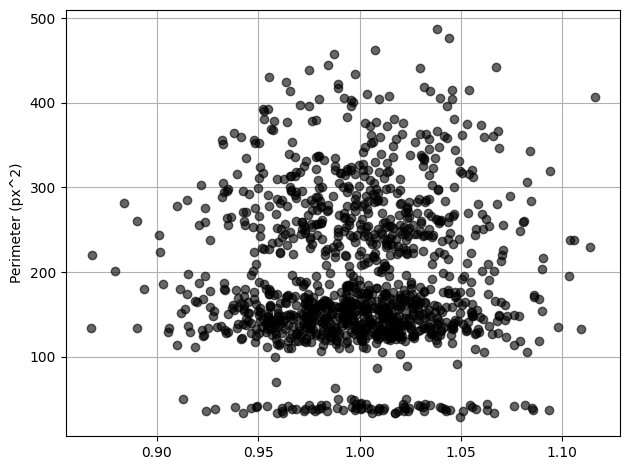

In [44]:
# Plot perimeteres
for blobs in total_blobs: # blobs in each image
    for blob in blobs:
        y = blob["perimeter"]
        x = np.random.normal(1, 0.04, size=1)  # jitter en vertical
        plt.plot(x, y, "o", alpha=0.6, color="black")
plt.ylabel("Perimeter (px^2)")
plt.grid(True)
plt.tight_layout()
#plt.title("Distribución de valores (Boxplot)")
plt.show()

In [45]:
#concluimos añadiendo etiqueta al blob si hay o no solapamiento, según su área.
# observando las gráficas (luego se le puede dar una matemática)

mice_area_mean = statistics.mean(mice_areas)
mice_area_std = statistics.stdev(mice_areas)


# Esto ya se hace más arriba...
#for blobs in total_blobs:
#    for blob in blobs:
#        if blob["area"] < MIN_AREA:
#            blob["type"] = 0 # no mice
#        elif (blob["area"] >= MIN_AREA) & (blob["area"] <= MAX_AREA) :
#            blob["type"] = 1 # one mice
#        elif blob["area"] > mice_area_mean + mice_area_std:
#            blob["type"] = 2 # more than one mice



In [46]:
print(mice_area_mean + 2*mice_area_std)
print(mice_area_mean - 2*mice_area_std)

1704.7220067254061
563.3180549078755


Calibración de [d,l,S] para el convexity defects

 * S, superficie del raton en un rango [Smin, Smax] marcado por los diagramas anteriores
 * l, longitud mínima a la que poder segmentar
 * D, distancia umbral.
 * np, numero de puntos de inflexión. Límites dentro de un rango marcado por el numero de ratones. 

 Representar en cada blob con/sin solapamiento, la distancia "D" de los candidatos a puntos de inflexión


In [47]:
print(blob.keys())

dict_keys(['id', 'img_path', 'n_blobs_in_image', 'n_mice', 'contour', 'origin', 'size', 'roi_image', 'area', 'perimeter', 'iou', 'rs', 'rect_similarity', 'type', 'ellipses', 'ellipse_area', 'hull', 'split_contours', 'segments', 'intersections', 'inter_points', 'widths', 'distances', 'D_final'])


In [54]:
# defectos de convexitud según el tipo de blob (0, 1 o 2)
df_defects ={
    "scores_0":[]
    , "scores_1":[]
    , "scores_2":[]
    , "d_0":[]
    , "d_1":[]
    , "d_2":[]
    , "w_0":[]
    , "w_1":[]
    , "w_2":[]
}
for blobs in total_blobs:
    for blob in blobs:
        contour = blob["contour"]
        contour = contour.squeeze()  # Elimina dimensiones extra si es necesario
        contour.tolist()
        blob["contour"] = contour

        blob["hull"] = cv.convexHull(contour)
        blob["d"] = []
        try:
            hull_idx = cv.convexHull(contour, returnPoints=False)
            defects = cv.convexityDefects(contour, hull_idx)
        except Exception as e:
            print(f"Error occurred while computing convexity defects for blob: {e}")
            hull_idx = None
            defects = None
            continue

#        distancias = np.zeros(len(blob["contour"]))
#        widths = np.zeros(len(blob["contour"]))
#        scores = np.zeros(len(blob["contour"]))

        distancias = np.zeros(len(blob["contour"]))
        widths = np.zeros(len(blob["contour"]))
        scores = np.zeros(len(blob["contour"]))
#        print(len(blob["contour"]))
        if defects is not None :
#            for i, defect in enumerate(np.squeeze(defects, 1)):#defects.shape[0]):
            for i in range( defects.shape[0] ):
              s,e,f,dist = defects[i,0]
              start = tuple(contour[s])
              end = tuple(contour[e])
              far = tuple(contour[f])
              distancias[f] = dist
              width = np.linalg.norm(np.array(start) - np.array(end))
              widths[f] = width
              scores[f] = dist*width              
#            print(scores)
              if blob["type"] == 0: # no mice: area too small
                  df_defects["scores_0"].append(dist*width)
                  df_defects["d_0"].append(dist)
                  df_defects["w_0"].append(width)
              elif blob["type"] == 1: # 1 mice
                  df_defects["scores_1"].append(dist*width)
                  df_defects["d_1"].append(dist)
                  df_defects["w_1"].append(width)
              elif blob["type"] == 2: # at least 2 mice: area too big
                  df_defects["scores_2"].append(dist*width)
                  df_defects["d_2"].append(dist)
                  df_defects["w_2"].append(width)
        blob["distancias"] = distancias
        blob["widths"] = widths
        blob["scores"] = scores
#        print(blob["contour"])
#        print(blob["distancias"])
    #          print(d)
    #          for n, p in enumerate(blob["inter_points"]):
    #          cv.circle(frame_defects, p, 3, (0,0,255))



Error occurred while computing convexity defects for blob: OpenCV(4.10.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\convhull.cpp:360: error: (-5:Bad argument) The convex hull indices are not monotonous, which can be in the case when the input contour contains self-intersections in function 'cv::convexityDefects'



No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


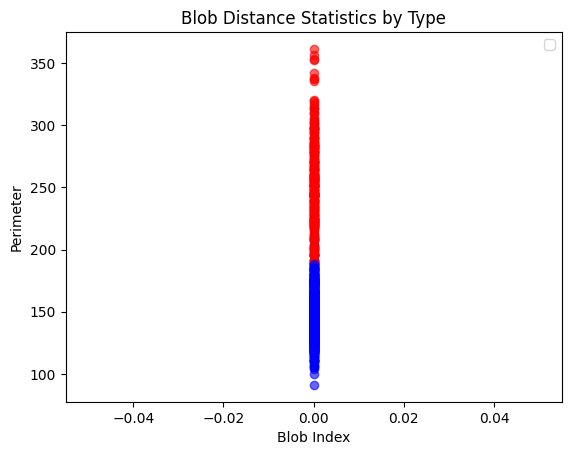

In [55]:
# Plot blob["contour"] statistics by blob["type"]:
for blobs in total_blobs:
    for blob in blobs:
        if blob["type"] == 0:
            plt.plot(blob["perimeter"], "o", alpha=0.6, color="black")
        elif blob["type"] == 1:
            plt.plot(blob["perimeter"], "o", alpha=0.6, color="blue")
        elif blob["type"] == 2:
            plt.plot(blob["perimeter"], "o", alpha=0.6, color="red")
plt.xlabel("Blob Index")
plt.ylabel("Perimeter")
plt.title("Blob Distance Statistics by Type")
plt.legend()
plt.show()


In [56]:
print(len(blob["distancias"]))
print(range(len(blob["contour"])))

225
range(0, 225)


In [57]:
print(df_defects.keys())

dict_keys(['scores_0', 'scores_1', 'scores_2', 'd_0', 'd_1', 'd_2', 'w_0', 'w_1', 'w_2'])


In [58]:
print(blob.keys())

dict_keys(['id', 'img_path', 'n_blobs_in_image', 'n_mice', 'contour', 'origin', 'size', 'roi_image', 'area', 'perimeter', 'iou', 'rs', 'rect_similarity', 'type', 'ellipses', 'ellipse_area', 'hull', 'split_contours', 'segments', 'intersections', 'inter_points', 'widths', 'distances', 'D_final', 'd', 'distancias', 'scores'])


In [59]:
print(df_defects["scores_0"])

[]


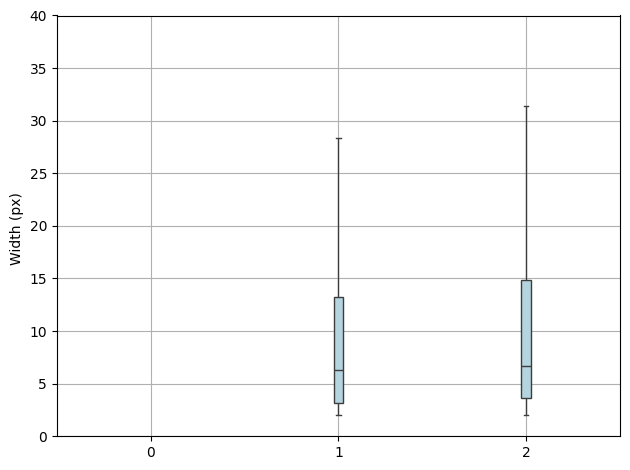

In [60]:
#plt.violinplot(distances_0, vert=False, widths=0.5, showmeans = True)
#sns.violinplot(data = [distances_1, distances_2], alpha = 0.6, inner_kws=dict(box_width=15, whis_width=2, color=".8"))
#sns.boxplot([df_defects["scores_0"],df_defects["scores_1"],df_defects["scores_2"]], width=0.05,color="lightblue", fliersize=0)
sns.boxplot([df_defects["w_0"],df_defects["w_1"],df_defects["w_2"]], width=0.05,color="lightblue", fliersize=0)
#plt.boxplot(data=[distances_1, distances_2])


#plt.xlim(-100,2000)
plt.ylim(0,40)
plt.ylabel("Width (px) ")
plt.grid(True)
plt.tight_layout()
plt.show()

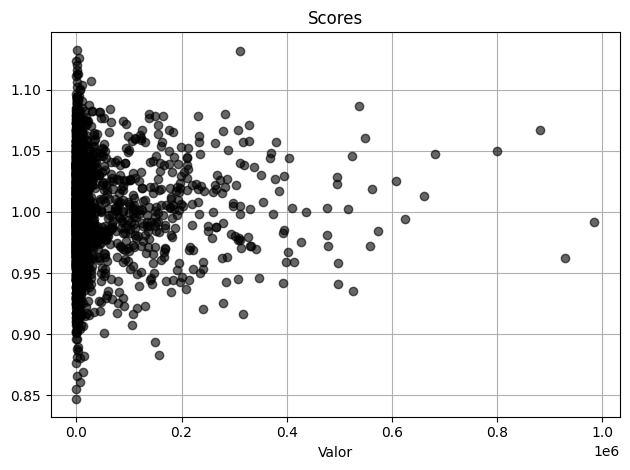

In [61]:
x = df_defects["scores_2"]  # cuando solamente hay un raton
y = np.random.normal(1, 0.04, size=len(x))  # jitter en vertical
plt.plot(x, y, "o", alpha=0.6, color="black")
#plt.xlim(-50, 1000)
plt.xlabel("Valor")
plt.title("Scores")
plt.grid(True)
plt.tight_layout()
plt.show()

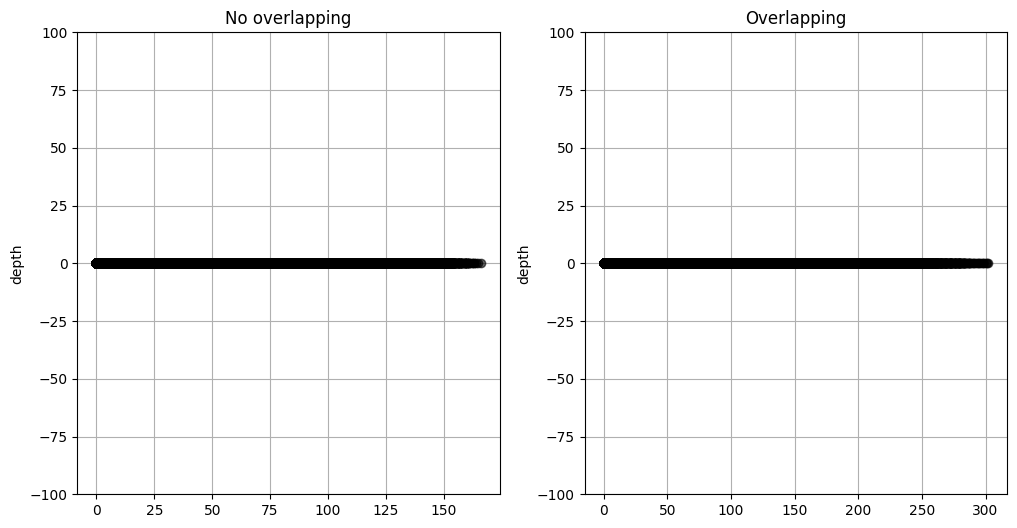

In [64]:
try:
    y_max = max(max(df_defects["d_0"]), max(df_defects["d_1"]), max(df_defects["d_2"]))
except ValueError:
    y_max = 100
plt.figure(figsize=(12,6))
#plt.figure()
ax1 = plt.subplot(121)
for blobs in total_blobs:
    for b in blobs:
        cnt = b["contour"]
        distancias = b["distancias"]
        if b["type"] == 1:
            if distancias.any() > 0:
                ax1.plot(range(len(cnt)), distancias,'o', alpha=0.6, color="black" )
plt.ylim(-100, y_max)
plt.title("No overlapping")
plt.ylabel("depth")
plt.grid(True)

ax2 = plt.subplot(122)
for blobs in total_blobs:
    for b in blobs:
        cnt = b["contour"]
        distancias = b["distancias"]
        if b["type"] == 2:
            if distancias.any() > 0:
                ax2.plot(range(len(cnt)), distancias,'o', alpha=0.6, color="black")
plt.ylim(-100, y_max)
plt.title("Overlapping")
plt.ylabel("depth")
plt.grid(True)


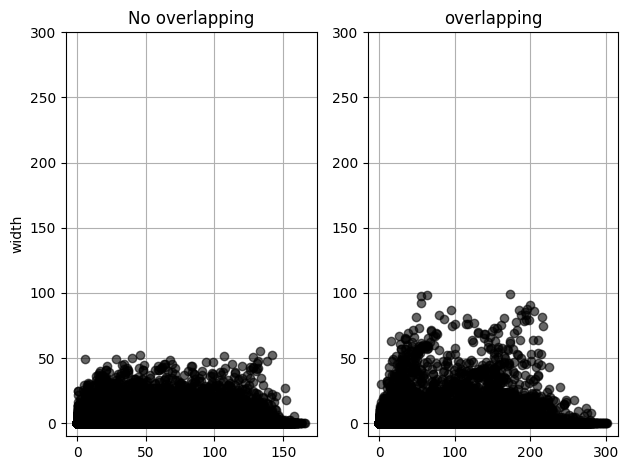

In [65]:

ax3 = plt.subplot(121)
for blobs in total_blobs:
    for b in blobs:
        cnt = b["contour"]
        distancias = b["widths"]
        if b["type"] == 1:
            if distancias.any() > 0:
                ax3.plot(range(len(cnt)), distancias,'o', alpha=0.6, color="black",label=f'Blob {idx+1}' )
plt.ylim(-10,300)
plt.title("No overlapping")
plt.ylabel("width")
#plt.xlabel("Contour point")
plt.grid(True)
ax4 = plt.subplot(122)
for blobs in total_blobs:
    for b in blobs:
        cnt = b["contour"]
        distancias = b["widths"]
        if b["type"] == 2:
            if distancias.any() > 0:
                ax4.plot(range(len(cnt)), distancias,'o', alpha=0.6, color="black",label=f'Blob {idx+1}' )
plt.ylim(-10,300)
plt.title("overlapping")
#plt.xlabel("Contour point")
plt.grid(True)
plt.tight_layout()
plt.show()


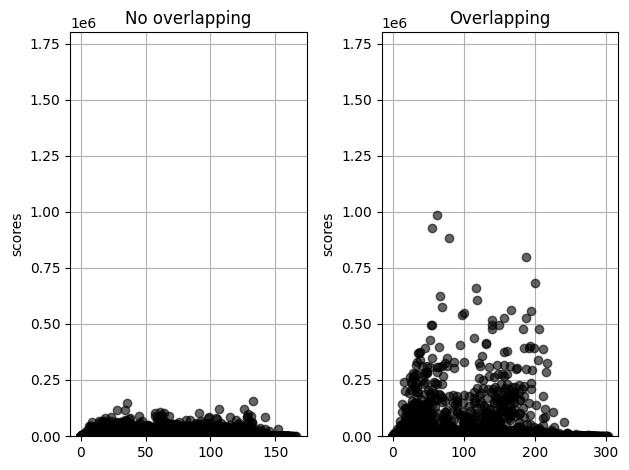

In [66]:
ax5 = plt.subplot(121)
for blobs in total_blobs:
    for b in blobs:
        cnt = b["contour"]
        distancias = b["scores"]
        if b["type"] == 1:
            if distancias.any() > 0:
                ax5.plot(range(len(cnt)), distancias,'o', alpha=0.6, color="black",label=f'Blob {idx+1}' )
plt.ylim(-1000,1800000)
plt.title("No overlapping")
plt.ylabel("scores")
#plt.xlabel("Contour point")
plt.grid(True)

ax6 = plt.subplot(122)
for blobs in total_blobs:
    for b in blobs:
        cnt = b["contour"]
        distancias = b["scores"]
        if b["type"] == 2:
            if distancias.any() > 0:
                ax6.plot(range(len(cnt)), distancias,'o', alpha=0.6, color="black",label=f'Blob {idx+1}' )
plt.ylim(-1000,1800000)
plt.title("Overlapping")
plt.ylabel("scores")
#plt.xlabel("Contour point")
plt.tight_layout()
plt.grid(True)
plt.show()



## EVALUATION.
### Cálculo de TP, TN, FP, FN.
* TP: Elipses cuyo RMSE respecto al punto ground truth más cercano es menor que un umbral.
* TN: Elipses cuyo RMSE... es mayor que el umbral.
* FN: Ratones que no se han encontrado.
 


Convertimos el DF de blobs en DF img con las columnas:
* img_path num_blobs numb_mice mus_i_x/y mus_i_type mus_i_area


In [72]:
df_blobs.columns

Index(['id', 'img_path', 'n_blobs_in_image', 'n_mice', 'contour', 'origin',
       'size', 'roi_image', 'area', 'perimeter', 'iou', 'rs',
       'rect_similarity', 'type', 'ellipses', 'ellipse_area', 'hull',
       'split_contours', 'segments', 'intersections', 'inter_points', 'widths',
       'distances', 'D_final'],
      dtype='object')

In [73]:
df_blobs["id"][4]

1

In [74]:
df_blobs.head(10)

,id,img_path,n_blobs_in_image,n_mice,contour,origin,size,roi_image,area,perimeter,...,ellipses,ellipse_area,hull,split_contours,segments,intersections,inter_points,widths,distances,D_final
0,0,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,3,1,"[[[14, 93]], [[13, 94]], [[12, 95]], [[11, 96]...","(0, 93)","(31, 60)","[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 25...",1239.5,154.267026,...,"[((14.713443756103516, 125.9930648803711), (28...",[1316.7516487338867],None,[],NaN,NaN,NaN,NaN,NaN,NaN
1,1,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,3,1,"[[[289, 39]], [[288, 40]], [[287, 40]], [[286,...","(278, 39)","(40, 26)","[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 255, 255, 0...",620.5,106.953318,...,"[((295.7978515625, 50.52449417114258), (22.194...",[664.1766791288796],None,[],NaN,NaN,NaN,NaN,NaN,NaN
2,2,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,3,1,"[[[235, 7]], [[234, 8]], [[233, 8]], [[232, 8]...","(216, 7)","(72, 29)","[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1403.5,170.610172,...,"[((247.77865600585938, 20.303377151489258), (2...",[1470.4353764504524],None,[],NaN,NaN,NaN,NaN,NaN,NaN
3,0,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,3,1,"[[[14, 93]], [[13, 94]], [[12, 95]], [[11, 96]...","(0, 93)","(33, 61)","[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 25...",1341.0,159.338094,...,"[((15.14417839050293, 126.32186126708984), (30...",[1410.950911907722],None,[],NaN,NaN,NaN,NaN,NaN,NaN
4,1,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,3,1,"[[[292, 54]], [[291, 55]], [[290, 55]], [[289,...","(277, 54)","(40, 46)","[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",936.0,134.509666,...,"[((297.6183776855469, 73.79840087890625), (25....",[1025.3091245493774],None,[],NaN,NaN,NaN,NaN,NaN,NaN
5,2,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,3,1,"[[[262, 3]], [[261, 4]], [[260, 4]], [[259, 5]...","(244, 3)","(72, 31)","[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1479.0,176.166521,...,"[((275.44696044921875, 18.319910049438477), (2...",[1579.9298207171223],None,[],NaN,NaN,NaN,NaN,NaN,NaN
6,0,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,3,1,"[[[14, 93]], [[13, 94]], [[12, 95]], [[11, 96]...","(0, 93)","(33, 61)","[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 25...",1328.0,158.166521,...,"[((15.322511672973633, 125.61217498779297), (3...",[1405.323197478164],None,[],NaN,NaN,NaN,NaN,NaN,NaN
7,1,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,3,1,"[[[302, 81]], [[301, 82]], [[300, 83]], [[299,...","(292, 81)","(27, 55)","[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 255, 255, 255,...",960.5,134.124890,...,"[((304.49652099609375, 105.47000122070312), (2...",[1014.6296409268981],None,[],NaN,NaN,NaN,NaN,NaN,NaN
8,2,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,3,1,"[[[264, 1]], [[263, 2]], [[262, 2]], [[261, 2]...","(247, 1)","(67, 37)","[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1468.5,175.095453,...,"[((277.8798828125, 18.472524642944336), (30.93...",[1660.2562802600364],None,[],NaN,NaN,NaN,NaN,NaN,NaN
9,0,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,3,1,"[[[298, 119]], [[297, 120]], [[296, 121]], [[2...","(288, 119)","(28, 53)","[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 255, 255, 255,...",927.0,131.539104,...,"[((301.01922607421875, 142.45664978027344), (2...",[982.8293001598729],None,[],NaN,NaN,NaN,NaN,NaN,NaN


In [75]:
df_blobs.describe()

,id,n_blobs_in_image,n_mice,area,perimeter,iou,rs,rect_similarity,type
count,1208.000000,1208.000000,1208.000000,1208.000000,1208.000000,1208.000000,1208.000000,1208.000000,1122.000000
mean,0.690397,2.380795,1.314570,1841.691639,195.028296,0.807128,0.876379,0.763100,1.601604
std,0.801928,0.872499,0.729576,1197.354824,87.994052,0.079536,0.066365,0.051436,0.764347
min,0.000000,1.000000,0.000000,36.000000,28.970562,0.391728,0.659323,0.611003,1.000000
25%,0.000000,2.000000,1.000000,987.750000,136.786056,0.779120,0.851184,0.730535,1.000000
50%,1.000000,2.000000,1.000000,1400.750000,166.287841,0.830954,0.900926,0.767995,1.000000
75%,1.000000,3.000000,2.000000,2659.125000,255.866790,0.858049,0.921466,0.801209,2.000000
max,3.000000,4.000000,3.000000,5249.500000,486.641697,0.928742,0.958694,0.909489,3.000000


posx and posy should be finite values
posx and posy should be finite values


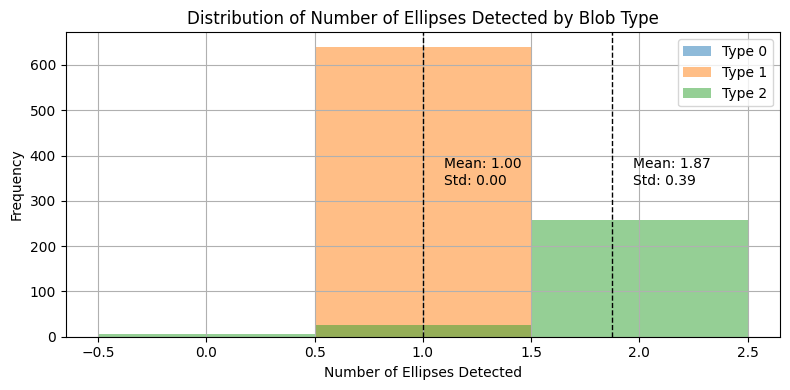

In [76]:
# TODO: generar datos por raton en funcion de la cantidad de elipses detectadas en cada blob, teniendo en cuenta que en cada fichero de imagen, img_path, hay siempre 3 ratones
# representación gráfica del número de elipses detectadas por cada blob, según su tipo (0, 1 o 2)
# Para el tipo 0 (no mice), el número de elipses detectadas debería ser 0.
# Para el tipo 1 (single mice), el número de elipses detectadas debería ser 1.
# Para el tipo 2 (overlapping mice), el número de elipses detectadas debería ser 2 o más.
# Se puede usar un gráfico de barras o un histograma para mostrar la distribución del número de elipses detectadas por cada tipo de blob. Además, se puede calcular la media y la desviación estándar del número de elipses detectadas para cada tipo de blob y mostrarlo en el gráfico.    
max_n = df_blobs[df_blobs["type"]==2]["ellipses"].apply(len).max()
plt.figure(figsize=(8,4))
for t in [0,1,2]:
    n_ellipses = df_blobs[df_blobs["type"]==t]["ellipses"].apply(len)
    plt.hist(n_ellipses, bins=range(0, max_n+2), alpha=0.5, label=f'Type {t}', align='left')
    mean_n = n_ellipses.mean()
    std_n = n_ellipses.std()
    plt.axvline(mean_n, color='k', linestyle='dashed', linewidth=1)
    plt.text(mean_n + 0.1, plt.ylim()[1]*0.5, f'Mean: {mean_n:.2f}\nStd: {std_n:.2f}', color='k')
plt.xlabel('Number of Ellipses Detected')
plt.ylabel('Frequency')
plt.title('Distribution of Number of Ellipses Detected by Blob Type')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [77]:
df_blobs["ellipse_area"].apply(len).max()

3

In [78]:

max_n = df_blobs["ellipses"].apply(len).max()
#max_n = 3

# --- Crear las columnas dinámicamente ---
for i in range(max_n):
    df_blobs[f"mus_{i+1}_x"] = df_blobs["ellipses"].apply(
        lambda lst: lst[i][0][0] if i < len(lst) else None
    )
    df_blobs[f"mus_{i+1}_y"] = df_blobs["ellipses"].apply(
        lambda lst: lst[i][0][1] if i < len(lst) else None
    )
    df_blobs[f"mus_{i+1}_type"] = df_blobs["type"]  # mismo valor para todas las elipses de esa fila
    df_blobs[f"mus_{i+1}_area"] = df_blobs["ellipse_area"].apply(
        lambda lst: lst[i] if i < len(lst) else None
    )   
# --- Resultado ---
#print(df_blobs.drop(columns=["ellipses"]))


In [79]:
df_blobs.describe()


,id,n_blobs_in_image,n_mice,area,perimeter,iou,rs,rect_similarity,type,mus_1_x,...,mus_1_type,mus_1_area,mus_2_x,mus_2_y,mus_2_type,mus_2_area,mus_3_x,mus_3_y,mus_3_type,mus_3_area
count,1208.000000,1208.000000,1208.000000,1208.000000,1208.000000,1208.000000,1208.000000,1208.000000,1122.000000,1113.000000,...,1122.000000,1113.000000,445.000000,445.000000,1122.000000,445.000000,161.000000,161.000000,1122.000000,161.000000
mean,0.690397,2.380795,1.314570,1841.691639,195.028296,0.807128,0.876379,0.763100,1.601604,166.779182,...,1.601604,1252.247102,171.427279,68.550923,1.601604,1451.027036,155.627397,64.522826,1.601604,1474.217767
std,0.801928,0.872499,0.729576,1197.354824,87.994052,0.079536,0.066365,0.051436,0.764347,103.757871,...,0.764347,378.633283,107.715806,52.806049,0.764347,431.807958,111.274155,51.081554,0.764347,518.893548
min,0.000000,1.000000,0.000000,36.000000,28.970562,0.391728,0.659323,0.611003,1.000000,7.039988,...,1.000000,217.409996,9.968477,6.898293,1.000000,199.764437,12.366583,11.130697,1.000000,204.691958
25%,0.000000,2.000000,1.000000,987.750000,136.786056,0.779120,0.851184,0.730535,1.000000,60.199799,...,1.000000,984.231162,64.330307,24.339771,1.000000,1175.214810,45.273769,19.884190,1.000000,1154.387164
50%,1.000000,2.000000,1.000000,1400.750000,166.287841,0.830954,0.900926,0.767995,1.000000,168.143021,...,1.000000,1234.026840,162.175552,45.390556,1.000000,1467.159817,115.574600,40.643761,1.000000,1499.730870
75%,1.000000,3.000000,2.000000,2659.125000,255.866790,0.858049,0.921466,0.801209,2.000000,271.226196,...,2.000000,1497.754315,286.374573,127.514877,2.000000,1710.964206,278.231537,118.658554,2.000000,1881.158568
max,3.000000,4.000000,3.000000,5249.500000,486.641697,0.928742,0.958694,0.909489,3.000000,310.655487,...,3.000000,2360.188479,309.234009,203.542191,3.000000,2348.984800,308.905334,172.501801,3.000000,2331.764119


In [93]:
df_img = pd.DataFrame()
# copiamos df_blobs pero solamente las columnas img_path, type, mus_1_x, mus_1_y, mus_2_x, mus_2_y, mus_3_x, mus_3_y
#df_img = df_blobs[["img_path","mus_1_x", "mus_1_y",  "mus_1_type", "mus_1_area", "mus_2_x", "mus_2_y", "mus_2_type", "mus_2_area"]].copy()
df_img = df_blobs[["img_path","mus_1_x", "mus_1_y",  "mus_1_type", "mus_1_area", "mus_2_x", "mus_2_y", "mus_2_type", "mus_2_area", "mus_3_x", "mus_3_y", "mus_3_type", "mus_3_area"]].copy()
df_img.head(6)

,img_path,mus_1_x,mus_1_y,mus_1_type,mus_1_area,mus_2_x,mus_2_y,mus_2_type,mus_2_area,mus_3_x,mus_3_y,mus_3_type,mus_3_area
0,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,14.713444,125.993065,1.0,1316.751649,NaN,NaN,1.0,NaN,NaN,NaN,1.0,NaN
1,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,295.797852,50.524494,1.0,664.176679,NaN,NaN,1.0,NaN,NaN,NaN,1.0,NaN
2,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,247.778656,20.303377,1.0,1470.435376,NaN,NaN,1.0,NaN,NaN,NaN,1.0,NaN
3,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,15.144178,126.321861,1.0,1410.950912,NaN,NaN,1.0,NaN,NaN,NaN,1.0,NaN
4,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,297.618378,73.798401,1.0,1025.309125,NaN,NaN,1.0,NaN,NaN,NaN,1.0,NaN
5,/240712_3w_148b_151b_154b_m_rec_1000model_mp4-...,275.446960,18.319910,1.0,1579.929821,NaN,NaN,1.0,NaN,NaN,NaN,1.0,NaN


In [94]:
# Construccion de un DF con todas las filas de un mismo img_path fusionadas
# y las columnas mus_i_x, mus_i_y, mus_i_type renumeradas consecutivamente
# Este df es el resultado del reconocimiento de ratones en cada imagen.


def merge_blob_rows(df_blob):
    # Detectar todas las columnas mus_i_x, mus_i_y, mus_i_type
    mus_cols = [c for c in df_blob.columns if c.startswith("mus_")]
    
    # Grupo por img_path
    grouped = df_blob.groupby("img_path")
    merged_rows = []
    for img_path, group in grouped:
        # quitar el simbolo "/" al inicio de la ruta de la imagen si existe
        if img_path.startswith("/"):
            img_path = img_path[1:]
        new_row = {"img_path": img_path}
        i_new = 1  # índice acumulativo para nueva numeración
        
        # recorrer cada fila del grupo
        for _, row in group.iterrows():
            # buscar todas las parejas mus_i_x/y/type válidas
            for i in range(1, 100):  # límite alto por seguridad
                x_col, y_col, t_col, s_col = f"mus_{i}_x", f"mus_{i}_y", f"mus_{i}_type", f"mus_{i}_area"
                if s_col not in row or pd.isna(row[s_col]):
                    continue
                # copiar datos a nuevas columnas consecutivas
                new_row[f"mus_{i_new}_x"] = row[x_col]
                new_row[f"mus_{i_new}_y"] = row[y_col]
                new_row[f"mus_{i_new}_type"] = row[t_col]
                new_row[f"mus_{i_new}_area"] = row[s_col]
                i_new += 1
                
        merged_rows.append(new_row)
    
    # reconstruir dataframe fusionado
    df_merged = pd.DataFrame(merged_rows)
    return df_merged

# --- ejemplo de uso ---
df_merged = merge_blob_rows(df_blobs)
df_merged.head(10)

,img_path,mus_1_x,mus_1_y,mus_1_type,mus_1_area,mus_2_x,mus_2_y,mus_2_type,mus_2_area,mus_3_x,mus_3_y,mus_3_type,mus_3_area
0,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,14.713444,125.993065,1.0,1316.751649,295.797852,50.524494,1.0,664.176679,247.778656,20.303377,1.0,1470.435376
1,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,15.144178,126.321861,1.0,1410.950912,297.618378,73.798401,1.0,1025.309125,275.446960,18.319910,1.0,1579.929821
2,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,15.322512,125.612175,1.0,1405.323197,304.496521,105.470001,1.0,1014.629641,277.879883,18.472525,1.0,1660.256280
3,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,301.019226,142.456650,1.0,982.829300,15.506021,125.773170,1.0,1444.192843,279.087036,18.247387,1.0,1652.619242
4,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,297.971344,145.214401,1.0,991.286439,15.755831,125.635521,1.0,1447.315045,279.909760,19.326281,1.0,1647.229838
5,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,292.148773,147.586212,1.0,955.201760,15.986244,125.804451,1.0,1476.119179,280.304565,20.838627,1.0,1696.794785
6,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,269.342285,155.163361,1.0,914.344835,15.859162,125.702133,1.0,1476.526842,280.150909,20.558628,1.0,1699.688772
7,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,248.042618,162.540405,1.0,898.589837,15.901045,125.657028,1.0,1476.358968,280.095367,19.823713,1.0,1653.034485
8,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,217.333649,157.757874,1.0,910.160662,15.883549,125.664856,1.0,1477.038185,278.974518,17.626408,1.0,1536.226416
9,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,186.225098,156.265091,1.0,896.464212,15.921629,125.723846,1.0,1504.900142,283.259216,16.359158,1.0,1557.900196


In [ ]:
# Adaptamos los resultados al tamaño y forma original de las imágenes.
# esto implica, revertir el crop, y revertir el cambio de tamaño (resize) que se hizo al principio para procesar las imágenes.

scale_factor = RESIZE_FACTOR  # factor de escala para volver a tamaño original
for i in range(1, 10):  # suponiendo un máximo de 9 ratones por imagen
    x_col = f"mus_{i}_x"
    y_col = f"mus_{i}_y"
    area_col = f"mus_{i}_area"
    if x_col in df_merged.columns:
        df_merged[x_col] = df_merged[x_col] * scale_factor
        df_merged[x_col] = df_merged[x_col] + x_crop_min  # revertir el crop
    if y_col in df_merged.columns:
        df_merged[y_col] = df_merged[y_col] * scale_factor
        df_merged[y_col] = df_merged[y_col] + y_crop_min  # revertir el crop
    if area_col in df_merged.columns:
        df_merged[area_col] = df_merged[area_col] * (scale_factor ** 2)

# guardamos los resultados en un CSV
file_name = ruta_carpeta + "/"
file_name += "merged_blobs.csv"
df_merged.to_csv(file_name, index=False)


,img_path,mus_1_x,mus_1_y,mus_1_type,mus_1_area,mus_2_x,mus_2_y,mus_2_type,mus_2_area,mus_3_x,mus_3_y,mus_3_type,mus_3_area
0,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,248.280663,935.958389,1.0,47403.059354,1934.787109,483.146965,1.0,23910.360449,1646.671936,301.820263,1.0,52935.673552
1,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,250.865070,937.931168,1.0,50794.232829,1945.710266,622.790405,1.0,36911.128484,1812.681763,289.919460,1.0,56877.473546
2,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,251.935070,933.673050,1.0,50591.635109,1986.979126,812.820007,1.0,36526.667073,1827.279297,290.835148,1.0,59769.226089
3,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1966.115356,1034.739899,1.0,35381.854806,253.036123,934.639023,1.0,51990.942333,1834.522217,289.484322,1.0,59494.292708
4,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1947.828064,1051.286407,1.0,35686.311799,254.534985,933.813126,1.0,52103.341603,1839.458557,295.957684,1.0,59300.274165
5,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1912.892639,1065.517273,1.0,34387.263364,255.917465,934.826706,1.0,53140.290441,1841.827393,305.031761,1.0,61084.612260
6,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1776.053711,1110.980164,1.0,32916.414069,255.154974,934.212799,1.0,53154.966307,1840.905457,303.351768,1.0,61188.795781
7,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1648.255707,1155.242432,1.0,32349.234144,255.406269,933.942169,1.0,53148.922830,1840.572205,298.942280,1.0,59509.241450
8,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1464.001892,1126.547241,1.0,32765.783837,255.301292,933.989136,1.0,53173.374662,1833.847107,285.758446,1.0,55304.150967
9,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1277.350586,1117.590546,1.0,32272.711639,255.529774,934.343079,1.0,54176.405111,1859.555298,278.154945,1.0,56084.407043


In [ ]:
# imprime valors no Nan de la columna mus_4_area y dice en qué fila está
#for i, v in enumerate(df_merged["mus_4_area"]):
#    if not pd.isna(v):
#        print(f"Fila {i}: mus_4_area = {v}")    
#print(df_merged["img_path"][69  ])

In [26]:
# abrimos el dataframe from csv file:
file_name = ruta_carpeta + "/merged_blobs.csv"
df_merged = pd.read_csv(file_name)
df_merged.head(5)

,img_path,mus_1_x,mus_1_y,mus_1_type,mus_1_area,mus_2_x,mus_2_y,mus_2_type,mus_2_area,mus_3_x,mus_3_y,mus_3_type,mus_3_area
0,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,248.280663,935.958389,1.0,47403.059354,1934.787109,483.146965,1.0,23910.360449,1646.671936,301.820263,1.0,52935.673552
1,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,250.865070,937.931168,1.0,50794.232829,1945.710266,622.790405,1.0,36911.128484,1812.681763,289.919460,1.0,56877.473546
2,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,251.935070,933.673050,1.0,50591.635109,1986.979126,812.820007,1.0,36526.667073,1827.279297,290.835148,1.0,59769.226089
3,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1966.115356,1034.739899,1.0,35381.854806,253.036123,934.639023,1.0,51990.942333,1834.522217,289.484322,1.0,59494.292708
4,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1947.828064,1051.286407,1.0,35686.311799,254.534985,933.813126,1.0,52103.341603,1839.458557,295.957684,1.0,59300.274165


In [ ]:
# Representación gráfica del número de entradas por número de ratones detectados y tipo de blob
type_labels = {0: "noise blobs", 1: "single mice", 2: "overlapping mice"}
df_merged["n_mice"] = df_merged[[col for col in df_merged.columns if col.startswith("mus_") and col.endswith("_x")]].notna().sum(axis=1)
df_merged["type"] = df_merged[[col for col in df_merged.columns if col.startswith("mus_") and col.endswith("_type")]].max(axis=1)     
df_count = df_merged.groupby(["n_mice", "type"]).size().unstack(fill_value=0)
df_count = df_count.rename(columns=type_labels).sort_index()    
df_count.plot(kind="bar", stacked=True, figsize=(8,5), colormap="Set3")


In [ ]:
# Representación gráfica del número de blobs por tipo
type_labels = {0: "noise blobs", 1: "single mice", 2: "overlapping mice"}
df_blobs["type_label"] = df_blobs["type"].map(type_labels)
df_count = df_blobs["type_label"].value_counts().reindex(type_labels.values(), fill_value=0)
df_count.plot(kind="bar", figsize=(6,4), color=["lightblue", "lightgreen", "salmon"])
plt.ylabel("Number of blobs")   
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.grid(True)

In [ ]:
# Representación gráfica del número de ratones detectados en los blobs de tipo 1 y 2
df_mice = df_blobs[df_blobs["type"].isin([1,2])]
df_mice["n_mice"] = df_mice[[col for col in df_mice.columns if col.startswith("mus_") and col.endswith("_x")]].notna().sum(axis=1)
df_count = df_mice["n_mice"].value_counts().sort_index()
df_count.plot(kind="bar", figsize=(6,4), color=["lightgreen", "salmon"])
plt.ylabel("Number of blobs")
plt.xlabel("Number of mice detected in blob")
plt.grid(axis="y", linestyle="--", alpha=0.7)

In [ ]:
# Número de ratones detectados por imagen
# Número total de ratones detectados
df_merged["n_mice"] = df_merged[[col for col in df_merged.columns if col.startswith("mus_") and col.endswith("_x")]].notna().sum(axis=1)
df_count = df_merged["n_mice"].value_counts().sort_index()
df_count.plot(kind="bar", figsize=(6,4), color=["lightgreen", "salmon", "orange", "purple", "cyan"])
plt.ylabel("Number of images")
plt.xlabel("Number of mice detected in image")
plt.grid(axis="y", linestyle="--", alpha=0.7)


In [ ]:
# Número total de ratones detectados
total_mice = df_merged["n_mice"].sum()
print("Total mice detected:", total_mice)

# Numero total de imágenes procesadas
total_images = len(df_merged)
print("Total images processed:", total_images)  
print("Total number of mice:", total_images*3)

### Cargamos el groundtruth

Aquí hay que distinguir por dataset...

In [2]:
#Trimice
#test_file = r'C:\Users\inges\OneDrive - UDIT\src\photoneu\dataset\deeplabcut\labeled-data-ordered\CollectedData_dlc.csv'

#moveAI dataset
test_file = r'D:\src\photoneu\dataset\moveAI\moveAI_3_mice\ground_truth_centroids.csv'
df_ground_truth = pd.DataFrame()
df_ground_truth = pd.read_csv(test_file)
df_ground_truth.head(10)

NameError: name 'pd' is not defined

In [ ]:
# Solamente para Trimice dataset, para moveAI no hace falta
field = 'spine2'
#field = 'shoulder'
df_clean = pd.DataFrame()
df_clean["img_path"] = df_ground_truth["scorer"]
df_clean.drop([0,1,2], inplace=True)
col = df_ground_truth.loc[:, (df_ground_truth.iloc[0] == 'mus1') & (df_ground_truth.iloc[1] == field) & (df_ground_truth.iloc[2] == 'x')]
df_clean["mus_1_x"] = col
col = df_ground_truth.loc[:, (df_ground_truth.iloc[0] == 'mus1') & (df_ground_truth.iloc[1] == field) & (df_ground_truth.iloc[2] == 'y')]
df_clean["mus_1_y"] = col
col = df_ground_truth.loc[:, (df_ground_truth.iloc[0] == 'mus2') & (df_ground_truth.iloc[1] == field) & (df_ground_truth.iloc[2] == 'x')]
df_clean["mus_2_x"] = col
col = df_ground_truth.loc[:, (df_ground_truth.iloc[0] == 'mus2') & (df_ground_truth.iloc[1] == field) & (df_ground_truth.iloc[2] == 'y')]
df_clean["mus_2_y"] = col
col = df_ground_truth.loc[:, (df_ground_truth.iloc[0] == 'mus3') & (df_ground_truth.iloc[1] == field) & (df_ground_truth.iloc[2] == 'x')]
df_clean["mus_3_x"] = col
col = df_ground_truth.loc[:, (df_ground_truth.iloc[0] == 'mus3') & (df_ground_truth.iloc[1] == field) & (df_ground_truth.iloc[2] == 'y')]
df_clean["mus_3_y"] = col
df_ground_truth = df_clean
df_ground_truth.head(10)


In [28]:
df_ground_truth.head(5)

,img_path,width,height,num_mice,mus_1_xmin,mus_1_ymin,mus_1_xmax,mus_1_ymax,mus_2_xmin,mus_2_ymin,...,mus_3_xmin,mus_3_ymin,mus_3_xmax,mus_3_ymax,mus_1_x,mus_1_y,mus_2_x,mus_2_y,mus_3_x,mus_3_y
0,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1920,1080,3,186,560,331,834,1171,173,...,1379,320,1639,491,258,697,1337,248,1509,405
1,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1920,1080,3,1311,183,1629,314,1393,367,...,189,574,329,830,1470,248,1512,491,259,702
2,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1920,1080,3,1321,170,1623,326,1477,431,...,186,569,331,834,1472,248,1565,595,258,701
3,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1920,1080,3,187,560,326,834,1489,594,...,1340,163,1599,343,256,697,1559,751,1469,253
4,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1920,1080,3,189,566,330,829,1480,637,...,1343,163,1591,359,259,697,1556,779,1467,261


In [29]:
df_merged.head(10)

,img_path,mus_1_x,mus_1_y,mus_1_type,mus_1_area,mus_2_x,mus_2_y,mus_2_type,mus_2_area,mus_3_x,mus_3_y,mus_3_type,mus_3_area
0,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,248.280663,935.958389,1.0,47403.059354,1934.787109,483.146965,1.0,23910.360449,1646.671936,301.820263,1.0,52935.673552
1,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,250.865070,937.931168,1.0,50794.232829,1945.710266,622.790405,1.0,36911.128484,1812.681763,289.919460,1.0,56877.473546
2,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,251.935070,933.673050,1.0,50591.635109,1986.979126,812.820007,1.0,36526.667073,1827.279297,290.835148,1.0,59769.226089
3,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1966.115356,1034.739899,1.0,35381.854806,253.036123,934.639023,1.0,51990.942333,1834.522217,289.484322,1.0,59494.292708
4,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1947.828064,1051.286407,1.0,35686.311799,254.534985,933.813126,1.0,52103.341603,1839.458557,295.957684,1.0,59300.274165
5,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1912.892639,1065.517273,1.0,34387.263364,255.917465,934.826706,1.0,53140.290441,1841.827393,305.031761,1.0,61084.612260
6,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1776.053711,1110.980164,1.0,32916.414069,255.154974,934.212799,1.0,53154.966307,1840.905457,303.351768,1.0,61188.795781
7,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1648.255707,1155.242432,1.0,32349.234144,255.406269,933.942169,1.0,53148.922830,1840.572205,298.942280,1.0,59509.241450
8,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1464.001892,1126.547241,1.0,32765.783837,255.301292,933.989136,1.0,53173.374662,1833.847107,285.758446,1.0,55304.150967
9,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1277.350586,1117.590546,1.0,32272.711639,255.529774,934.343079,1.0,54176.405111,1859.555298,278.154945,1.0,56084.407043


In [30]:
df_ground_truth.describe()

,width,height,num_mice,mus_1_xmin,mus_1_ymin,mus_1_xmax,mus_1_ymax,mus_2_xmin,mus_2_ymin,mus_2_xmax,...,mus_3_xmin,mus_3_ymin,mus_3_xmax,mus_3_ymax,mus_1_x,mus_1_y,mus_2_x,mus_2_y,mus_3_x,mus_3_y
count,598.0,598.0,598.0,598.000000,598.000000,598.000000,598.000000,598.000000,598.000000,598.000000,...,598.000000,598.000000,598.000000,598.000000,598.000000,598.000000,598.000000,598.000000,598.000000,598.000000
mean,1920.0,1080.0,3.0,769.520067,439.394649,1018.371237,614.314381,821.908027,411.632107,1049.608696,...,879.705686,407.148829,1086.394649,612.367893,893.707358,526.605351,935.521739,507.772575,982.806020,509.528428
std,0.0,0.0,0.0,452.976982,242.889042,458.706636,246.101445,487.606533,230.680673,483.416132,...,507.734810,223.432338,503.989669,224.819924,455.039347,243.496284,484.502413,228.797384,504.864603,222.379552
min,1920.0,1080.0,3.0,129.000000,117.000000,317.000000,268.000000,147.000000,122.000000,327.000000,...,112.000000,120.000000,306.000000,251.000000,255.000000,195.000000,260.000000,197.000000,223.000000,196.000000
25%,1920.0,1080.0,3.0,313.000000,196.000000,555.000000,367.500000,324.000000,205.250000,570.000000,...,338.000000,209.250000,576.250000,426.250000,431.000000,282.000000,438.250000,304.000000,450.250000,319.250000
50%,1920.0,1080.0,3.0,698.000000,367.500000,1010.500000,581.500000,744.500000,301.000000,1063.000000,...,953.500000,310.500000,1247.000000,550.500000,862.000000,481.000000,897.500000,406.500000,1100.000000,426.000000
75%,1920.0,1080.0,3.0,1260.000000,696.750000,1493.000000,871.750000,1316.000000,663.500000,1546.000000,...,1384.750000,643.000000,1585.000000,847.750000,1377.000000,787.750000,1436.750000,759.750000,1490.500000,743.750000
max,1920.0,1080.0,3.0,1503.000000,833.000000,1707.000000,971.000000,1548.000000,824.000000,1703.000000,...,1571.000000,858.000000,1718.000000,976.000000,1604.000000,893.000000,1599.000000,894.000000,1614.000000,903.000000


In [ ]:
# mostramos en las imagenes originales los ratones detectados por el algoritmo y los ratones del ground truth, para ver si coinciden.
# a partir de los dos dataframes df_merged y df_ground_truth, que contienen las coordenadas de los ratones detectados por el algoritmo y las coordenadas de los ratones del ground truth, respectivamente, podemos dibujar los puntos en las imágenes originales para comparar visualmente:
for i, img_path in enumerate(df_merged["img_path"]):
    # Leemos la imagen original
    img = cv.imread(os.path.join(ruta_carpeta, img_path))
    # Dibujamos los ratones detectados por el algoritmo
    for j in range(1, 4):
        x_col = f"mus_{j}_x"
        y_col = f"mus_{j}_y"
        if not pd.isna(df_merged.loc[i, x_col]) and not pd.isna(df_merged.loc[i, y_col]):
            cv.circle(img, (int(df_merged.loc[i, x_col]), int(df_merged.loc[i, y_col])), 12, (0, 255, 0), -1)  # verde
    # Dibujamos los ratones del ground truth
    for j in range(1, 4):
        x_col = f"mus_{j}_x"
        y_col = f"mus_{j}_y"
        if not pd.isna(df_ground_truth.loc[i, x_col]) and not pd.isna(df_ground_truth.loc[i, y_col]):
            cv.circle(img, (int(df_ground_truth.loc[i, x_col]), int(df_ground_truth.loc[i, y_col])), 512, (0, 0, 255), -1)  # rojo
    # Mostramos la imagen con los puntos dibujados
    plt.figure(figsize=(8, 6))
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(f"Image: {img_path}")
    plt.axis('off')
    plt.show()





[(248.2806625366211, 935.9583892822266), (1934.787109375, 483.14696502685547), (1646.6719360351562, 301.82026290893555)]
[(258, 697), (1337, 248), (1509, 405)]
[(250.86507034301758, 937.9311676025391), (1945.7102661132812, 622.7904052734375), (1812.6817626953125, 289.91946029663086)]
[(1470, 248), (1512, 491), (259, 702)]
[(251.9350700378418, 933.6730499267578), (1986.9791259765625, 812.8200073242188), (1827.279296875, 290.835147857666)]
[(1472, 248), (1565, 595), (258, 701)]
[(1966.1153564453125, 1034.7398986816406), (253.03612327575684, 934.6390228271484), (1834.522216796875, 289.4843215942383)]
[(256, 697), (1559, 751), (1469, 253)]
[(1947.8280639648438, 1051.2864074707031), (254.53498458862305, 933.8131256103516), (1839.4585571289062, 295.9576835632324)]
[(259, 697), (1556, 779), (1467, 261)]
[(1912.8926391601562, 1065.5172729492188), (255.91746520996094, 934.8267059326172), (1841.827392578125, 305.0317611694336)]
[(259, 695), (1472, 270), (1510, 771)]
[(1776.0537109375, 1110.98016

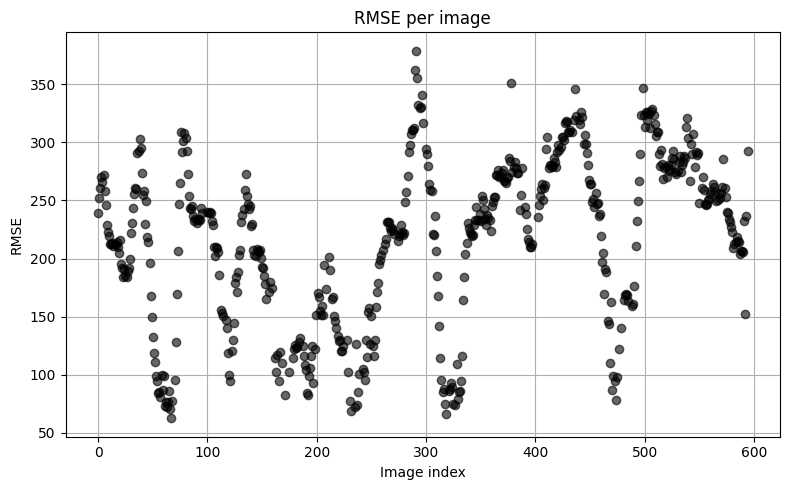

In [98]:
# Calculo de los RMSE entre las posiciones de los ratones detectados y las posiciones reales utilizando sklearn
# Cono los ID de los ratones (mus_1, mus_2, mus_3) no coincide con los ID de la verdad (mus1, mus2, mus3),
# calculamos todas las combinaciones posibles y nos quedamos con la que da menor RMSE
# Contabilizar también los casos en que no coinciden el número de ratones detectados y el número de ratones en la verdad
# Dar el resultado para el total de número de ratones detectados
# y también desglosado por número de ratones detectados (1, 2, 3, ...)
from sklearn.metrics import root_mean_squared_error
import itertools

def calculate_rmse(df_detected, df_truth):
    total_rmse = 0
    total_mice = 0
    mismatch_count = 0
    rmse_by_n_mice = {}
    rmse_values = []

    
    for _, row in df_detected.iterrows():
        img_path = row["img_path"]
        truth_row = df_truth[df_truth["img_path"] == img_path]
        if truth_row.empty:
            print(f"No ground truth found for image: {img_path}")
            continue
        
        # Obtener posiciones detectadas
        detected_positions = []
        for i in range(1, 10):  # suponiendo un máximo de 9 ratones por imagen
            x_col = f"mus_{i}_x"
            y_col = f"mus_{i}_y"
            if x_col in row and y_col in row and not pd.isna(row[x_col]) and not pd.isna(row[y_col]):
                detected_positions.append((row[x_col], row[y_col]))
        print(detected_positions)
        
        # Obtener posiciones de la verdad
        truth_positions = []
        for i in range(1, 4):  # suponiendo un máximo de 3 ratones en la verdad
            x_col = f"mus_{i}_x"
            y_col = f"mus_{i}_y"
            if x_col in truth_row.columns and y_col in truth_row.columns and not pd.isna(truth_row.iloc[0][x_col]) and not pd.isna(truth_row.iloc[0][y_col]):
                truth_positions.append((truth_row.iloc[0][x_col], truth_row.iloc[0][y_col]))
        print(truth_positions)
        
        n_detected = len(detected_positions)
        n_truth = len(truth_positions)
        
        if n_detected != n_truth:
            mismatch_count += 1
        
        if n_detected == 0 or n_truth == 0:
            continue
        
        # Calcular RMSE para todas las permutaciones posibles
        min_rmse = float('inf')
        best_rmse = np.inf
        best_perm = None
        for perm in itertools.permutations(detected_positions, min(n_detected, n_truth)):
#            print(perm)
            if len(perm) != len(truth_positions):
                continue
#            rmse = root_mean_squared_error(truth_positions, perm, squared=False)
            truth = np.asarray(truth_positions, dtype=float)
            pred = np.asarray(perm, dtype=float)
#            errors = np.linalg.norm(truth - pred, axis=1)
#            rmse = np.sqrt(np.mean(errors**2))
            rmse = np.sqrt(np.mean((truth - pred) ** 2))
            if rmse < best_rmse:
                best_rmse = rmse
                best_perm = perm
#                best_errors = errors
        
        total_rmse += best_rmse * min(n_detected, n_truth)
        total_mice += min(n_detected, n_truth)
        if n_truth not in rmse_by_n_mice:
            rmse_by_n_mice[n_truth] = {"total_rmse": 0, "count": 0}
        rmse_by_n_mice[n_truth]["total_rmse"] += best_rmse * min(n_detected, n_truth)
        rmse_by_n_mice[n_truth]["count"] += min(n_detected, n_truth)
        # Mostramos los resultados
        rmse_values.append(best_rmse)
    overall_rmse = total_rmse / total_mice if total_mice > 0 else 0
    print(f"Overall RMSE: {overall_rmse:.2f}")
    print(f"Total mice compared: {total_mice}")
    print(f"Images with mismatch in number of mice: {mismatch_count}")
    for n_mice, stats in rmse_by_n_mice.items():
        avg_rmse = stats["total_rmse"] / stats["count"] if stats["count"] > 0 else 0
        print(f"RMSE for images with {n_mice} mice: {avg_rmse:.2f} over {stats['count']} mice")
# Representación gráfica mediante puntos del RMSE individual para cada i de cada mus_i
    plt.figure(figsize=(8,5))
    plt.plot(range(len(rmse_values)), rmse_values, 'o', alpha=0.6, color="black")
    plt.xlabel("Image index")
    plt.ylabel("RMSE")
    plt.title("RMSE per image")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
        
    return overall_rmse
   

# --- ejemplo de uso ---
overall_rmse = calculate_rmse(df_merged, df_ground_truth)


In [ ]:
#TODO: hacerlo para que no tenga en cuenta valores np.inf o NaN en overall_rmse
#overall_rmse = [x for x in overall_rmse if not np.isinf(x) and not np.isnan(x)]
#print("Mean RMSE: %.2f px" % np.mean(overall_rmse))


In [99]:
# Calculo de los RMSE entre las posiciones de los ratones detectados y las posiciones reales utilizando sklearn
# Como los ID de los ratones (mus_1, mus_2, mus_3) no coincide con los ID de la verdad (mus1, mus2, mus3),
# calculamos todas las combinaciones posibles de un ratón detectado con cada ratón de la verdad
# y nos quedamos con la que da menor RMSE para ese ratón detectado.
# Repetimos para el siguiente ratón detectado, pero sin repetir los ratones de la verdad ya asignados. 
# Guardar para cada ratón detectado su RMSE individual como un campo nuevo en el dataframe df_merged
# y luego representamos gráficamente esos RMSE individuales
from math import perm

from sklearn.metrics import mean_squared_error
import itertools

def calculate_individual_rmse(df_detected, df_truth):
    individual_rmses = {f"mus_{i}_rmse": [] for i in range(1, 10)}
    
    for _, row in df_detected.iterrows():
        img_path = row["img_path"]
        truth_row = df_truth[df_truth["img_path"] == img_path]
        if truth_row.empty:
            continue
        
        detected_positions = []
        for i in range(1, 10):  # suponiendo un máximo de 9 ratones por imagen
            x_col = f"mus_{i}_x"
            y_col = f"mus_{i}_y"
            if x_col in row and y_col in row and not pd.isna(row[x_col]) and not pd.isna(row[y_col]):
                detected_positions.append((i, (row[x_col], row[y_col])))
        
        truth_positions = []
        for i in range(1, 4):  # suponiendo un máximo de 3 ratones en la verdad
            x_col = f"mus_{i}_x"
            y_col = f"mus_{i}_y"
            if x_col in truth_row.columns and y_col in truth_row.columns and not pd.isna(truth_row.iloc[0][x_col]) and not pd.isna(truth_row.iloc[0][y_col]):
                truth_positions.append((i, (truth_row.iloc[0][x_col], truth_row.iloc[0][y_col])))
        
        n_detected = len(detected_positions)
        n_truth = len(truth_positions)
        
        if n_detected == 0 or n_truth == 0:
            continue
        
        used_truth_indices = set()
        for det_idx, det_pos in detected_positions:
            min_rmse = float('inf')
            best_rmse = np.inf
            best_perm = None
            best_truth_idx = -1
            for truth_idx, truth_pos in truth_positions:
                if truth_idx in used_truth_indices:
                    continue

                truth = np.asarray(truth_pos, dtype=float)
                pred = np.asarray(det_pos, dtype=float)
                errors = np.linalg.norm(truth - pred)
#                rmse = np.sqrt(np.mean(errors**2))
                rmse = np.sqrt(np.mean((truth - pred) ** 2))

                if rmse < best_rmse:
                    best_rmse = rmse
                    best_perm = perm
                    best_errors = errors
                    best_truth_idx = truth_idx
            if best_truth_idx != -1:
                used_truth_indices.add(best_truth_idx)
                individual_rmses[f"mus_{det_idx}_rmse"].append(best_rmse)
            else:
                individual_rmses[f"mus_{det_idx}_rmse"].append(None)
                # No hay ratón de la verdad disponible para este ratón detectado
    # Añadir las columnas de RMSE individual al dataframe original
    for i in range(1, 10):
        rmse_col = f"mus_{i}_rmse"
        if rmse_col in individual_rmses:
            df_detected[rmse_col] = pd.Series(individual_rmses[rmse_col])
    return df_detected
# --- ejemplo de uso ---
df_merged = calculate_individual_rmse(df_merged, df_ground_truth)
df_merged.head()





,img_path,mus_1_x,mus_1_y,mus_1_type,mus_1_area,mus_2_x,mus_2_y,mus_2_type,mus_2_area,mus_3_x,...,mus_3_area,mus_1_rmse,mus_2_rmse,mus_3_rmse,mus_4_rmse,mus_5_rmse,mus_6_rmse,mus_7_rmse,mus_8_rmse,mus_9_rmse
0,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,248.280663,935.958389,1.0,47403.059354,1934.787109,483.146965,1.0,23910.360449,1646.671936,...,52935.673552,169.108807,306.105873,222.253604,NaN,NaN,NaN,NaN,NaN,NaN
1,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,250.865070,937.931168,1.0,50794.232829,1945.710266,622.790405,1.0,36911.128484,1812.681763,...,56877.473546,166.927668,320.525589,244.118856,NaN,NaN,NaN,NaN,NaN,NaN
2,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,251.935070,933.673050,1.0,50591.635109,1986.979126,812.820007,1.0,36526.667073,1827.279297,...,59769.226089,164.580575,335.791556,253.039749,NaN,NaN,NaN,NaN,NaN,NaN
3,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1966.115356,1034.739899,1.0,35381.854806,253.036123,934.639023,1.0,51990.942333,1834.522217,...,59494.292708,350.892607,168.049233,259.747567,NaN,NaN,NaN,NaN,NaN,NaN
4,240712_3w_148b_151b_154b_m_rec_1000model_mp4-0...,1947.828064,1051.286407,1.0,35686.311799,254.534985,933.813126,1.0,52103.341603,1839.458557,...,59300.274165,337.393775,167.481929,264.525440,NaN,NaN,NaN,NaN,NaN,NaN


In [1]:
df_merged.describe()

NameError: name 'df_merged' is not defined

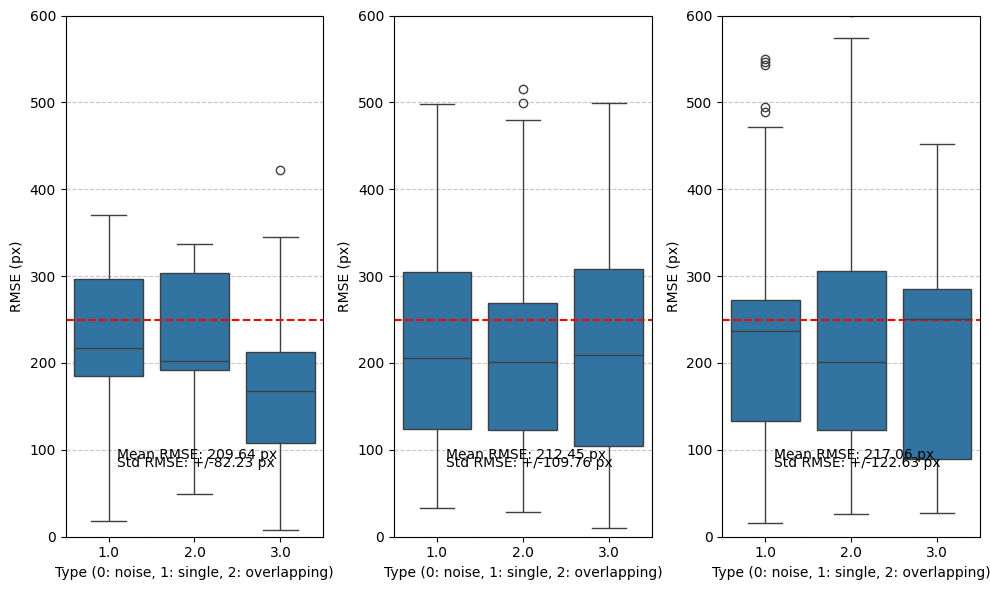

In [112]:
# Representar gráficamente los RMSE individuales según el mus_1_type, mus_2_type, mus_3_type
# Incluir como texto en la gráfica el RMSE medio para cada tipo de blob (0, 1, 2)

import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,6))
for i in range(1, 4):  # suponiendo un máximo de 3
    rmse_col = f"mus_{i}_rmse"
    type_col = f"mus_{i}_type"
    if rmse_col in df_merged.columns and type_col in df_merged.columns:
        plt.subplot(1, 3, i)
#        sns.boxplot(x=df_merged[type_col], y=df_merged[rmse_col], palette="Set3")
        sns.boxplot(x=df_merged[type_col], y=df_merged[rmse_col])
        plt.text(0.1, 90, f"Mean RMSE: {df_merged[rmse_col].mean():.2f} px", fontsize=10, color="black")
        plt.text(0.1, 80, f"Std RMSE: +/-{df_merged[rmse_col].std():.2f} px", fontsize=10, color="black")
        # Dibujamos una linea horizontal en el valor rmse=20
        plt.axhline(y=250, color='r', linestyle='--', label='Threshold 20 px')

        plt.xlabel("Type (0: noise, 1: single, 2: overlapping)")
        plt.ylabel("RMSE (px)")
        plt.ylim(0, 600)  # ajustar según los datos
        plt.grid(axis="y", linestyle="--", alpha=0.7)   
plt.tight_layout()
plt.show()  

In [105]:
# Contamos el número de valores de RMSE por encima de 20 px para cada mus_i_type
threshold = 300
for i in range(1, 4):
    rmse_col = f"mus_{i}_rmse"
    type_col = f"mus_{i}_type"
    if rmse_col in df_merged.columns and type_col in df_merged.columns:
        count_above_threshold = df_merged[df_merged[rmse_col] > threshold].groupby(type_col).size()
        print(f"mus_{i}_rmse counts above {threshold} px:")
        print(count_above_threshold)
# Consideramos True Positives como los ratones detectados (mus_i) con RMSE <= 20 px
# False Positives como los ratones detectados (mus_i) con RMSE > 20 px
# False Negatives como los ratones en la verdad (mus1, mus2, mus3) que no tienen ningún mus_i asignado con RMSE <= 20 px
# Calculamos Precision, Recall y F1-Score para cada mus_i_type
from sklearn.metrics import precision_score, recall_score, f1_score
def calculate_classification_metrics(df_detected, df_truth, threshold):
    metrics = {f"mus_{i}": {"TP": 0, "FP": 0, "FN": 0} for i in range(1, 10)}
    
    for _, row in df_detected.iterrows():
        img_path = row["img_path"]
        truth_row = df_truth[df_truth["img_path"] == img_path]
        if truth_row.empty:
            continue
        
        detected_positions = []
        for i in range(1, 10):
            x_col = f"mus_{i}_x"
            y_col = f"mus_{i}_y"
            rmse_col = f"mus_{i}_rmse"
            if x_col in row and y_col in row and rmse_col in row and not pd.isna(row[x_col]) and not pd.isna(row[y_col]) and not pd.isna(row[rmse_col]):
                detected_positions.append((i, row[rmse_col]))
        
        truth_positions = []
        for i in range(1, 4):
            x_col = f"mus_{i}_x"
            y_col = f"mus_{i}_y"
            if x_col in truth_row.columns and y_col in truth_row.columns and not pd.isna(truth_row.iloc[0][x_col]) and not pd.isna(truth_row.iloc[0][y_col]):
                truth_positions.append(i)
        
        detected_assigned = set()
        for det_idx, det_rmse in detected_positions:
            if det_rmse <= threshold:
                metrics[f"mus_{det_idx}"]["TP"] += 1
                detected_assigned.add(det_idx)
            else:
                metrics[f"mus_{det_idx}"]["FP"] += 1
        
        for truth_idx in truth_positions:
            if truth_idx not in detected_assigned:
                metrics[f"mus_{truth_idx}"]["FN"] += 1
    
    # Calcular Precision, Recall y F1-Score
    results = {}
    for mus, counts in metrics.items():
        TP = counts["TP"]
        FP = counts["FP"]
        FN = counts["FN"]
        precision = TP / (TP + FP) if (TP + FP) > 0 else 0
        recall = TP / (TP + FN) if (TP + FN) > 0 else 0
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        results[mus] = {"Precision": precision, "Recall": recall, "F1-Score": f1, "TP": TP, "FP": FP, "FN": FN}
    return results
# --- ejemplo de uso ---
metrics = calculate_classification_metrics(df_merged, df_ground_truth, threshold=300)
for mus, vals in metrics.items():
    print(f"{mus}: Precision={vals['Precision']:.2f}, Recall={vals['Recall']:.2f}, F1-Score={vals['F1-Score']:.2f}, TP={vals['TP']}, FP={vals['FP']}, FN={vals['FN']}")
    


mus_1_rmse counts above 300 px:
mus_1_type
1.0    77
2.0    17
3.0    11
dtype: int64
mus_2_rmse counts above 300 px:
mus_2_type
1.0    33
2.0    34
3.0    50
dtype: int64
mus_3_rmse counts above 300 px:
mus_3_type
1.0    22
2.0    45
3.0    26
dtype: int64
mus_1: Precision=0.82, Recall=0.81, F1-Score=0.82, TP=486, FP=105, FN=112
mus_2: Precision=0.80, Recall=0.76, F1-Score=0.78, TP=456, FP=117, FN=142
mus_3: Precision=0.80, Recall=0.64, F1-Score=0.71, TP=382, FP=93, FN=216
mus_4: Precision=0.00, Recall=0.00, F1-Score=0.00, TP=0, FP=0, FN=0
mus_5: Precision=0.00, Recall=0.00, F1-Score=0.00, TP=0, FP=0, FN=0
mus_6: Precision=0.00, Recall=0.00, F1-Score=0.00, TP=0, FP=0, FN=0
mus_7: Precision=0.00, Recall=0.00, F1-Score=0.00, TP=0, FP=0, FN=0
mus_8: Precision=0.00, Recall=0.00, F1-Score=0.00, TP=0, FP=0, FN=0
mus_9: Precision=0.00, Recall=0.00, F1-Score=0.00, TP=0, FP=0, FN=0


In [104]:
# Calculamos PRecision, Recall y F1-Score globales para todos los mus_i juntos
from sklearn.metrics import precision_score, recall_score, f1_score
def calculate_overall_metrics(df_detected, df_truth, threshold=30):
    total_TP = total_FP = total_FN = 0
    
    for _, row in df_detected.iterrows():
        img_path = row["img_path"]
        truth_row = df_truth[df_truth["img_path"] == img_path]
        if truth_row.empty:
            continue
        
        detected_positions = []
        for i in range(1, 10):
            x_col = f"mus_{i}_x"
            y_col = f"mus_{i}_y"
            rmse_col = f"mus_{i}_rmse"
            if x_col in row and y_col in row and rmse_col in row and not pd.isna(row[x_col]) and not pd.isna(row[y_col]) and not pd.isna(row[rmse_col]):
                detected_positions.append((i, row[rmse_col]))
        
        truth_positions = []
        for i in range(1, 4):
            x_col = f"mus_{i}_x"
            y_col = f"mus_{i}_y"
            if x_col in truth_row.columns and y_col in truth_row.columns and not pd.isna(truth_row.iloc[0][x_col]) and not pd.isna(truth_row.iloc[0][y_col]):
                truth_positions.append(i)
        
        detected_assigned = set()
        for det_idx, det_rmse in detected_positions:
            if det_rmse <= threshold:
                total_TP += 1
                detected_assigned.add(det_idx)
            else:
                total_FP += 1
        
        for truth_idx in truth_positions:
            if truth_idx not in detected_assigned:
                total_FN += 1
    
    precision = total_TP / (total_TP + total_FP) if (total_TP + total_FP) > 0 else 0
    recall = total_TP / (total_TP + total_FN) if (total_TP + total_FN) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    return {"Precision": precision, "Recall": recall, "F1-Score": f1, "TP": total_TP, "FP": total_FP, "FN": total_FN}
# --- ejemplo de uso ---
overall_metrics = calculate_overall_metrics(df_merged, df_ground_truth, threshold=300)
print(f"Overall: Precision={overall_metrics['Precision']:.2f}, Recall={overall_metrics['Recall']:.2f}, F1-Score={overall_metrics['F1-Score']:.2f}, TP={overall_metrics['TP']}, FP={overall_metrics['FP']}, FN={overall_metrics['FN']}")


Overall: Precision=0.81, Recall=0.74, F1-Score=0.77, TP=1324, FP=315, FN=470
